## Predictor de partidos de La Liga

En este notebook construyo un predictor del resultado de los partidos de La Liga (gana local, empate o gana visitante). Entreno con las temporadas anteriores a `2015/2016` (2660 partidos) y uso `2015/2016` como prueba final (380 partidos).

Agrego información por etapas y comparo los mismos cuatro clasificadores en cada una: identidad de los equipos, fuerza de plantilla, forma reciente y estilo táctico. Después pruebo un enfoque binario (gana local o no gana local), comparo el modelo contra las cuotas de las casas de apuestas y simulo la tabla general de la temporada. Cierro con las conclusiones y con la decisión sobre cómo seguirá este predictor.

> **Nota:** las cuotas de las casas de apuestas no entran como variables del modelo; las uso solo para evaluarlo.

In [ ]:
# Librerías para datos
import pandas as pd  # Tablas y matrices.
import numpy as np  # Álgebra lineal.


# Librerías para gráficas
import matplotlib.pyplot as plt  # Gráficas básicas.
import seaborn as sns  # Gráficas estadísticas.


# Modelos de clasificación
from sklearn.linear_model import LogisticRegression  # Regresión logística.
from sklearn.naive_bayes import GaussianNB  # Clasificación probabilística.
from sklearn.ensemble import RandomForestClassifier  # Clasificación por árboles.
from sklearn.tree import DecisionTreeClassifier  # Clasificación con árbol.
from sklearn.neighbors import KNeighborsClassifier  # Clasificación por vecinos.


# Escalado de variables
from sklearn.preprocessing import MinMaxScaler  # Escalado entre 0 y 1.


# Métricas
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support  # Métricas de clasificación.
from sklearn.metrics import log_loss  # Métrica de pérdida logarítmica.


# Medición de rendimiento
import time  # Tiempo de ejecución.
import tracemalloc  # Uso de memoria.

In [103]:
# Cargo el Dataset de partidos
df_match = pd.read_csv('../data/processed/clean/Match_Clean.csv')

# Exploración inicial
print(df_match.shape)
display(df_match.head())

# Revisión del conteo de valores nulos por columna
nulos = df_match.isnull().sum()
with pd.option_context('display.max_rows', None):
    display(nulos.to_frame(name='Cantidad de Nulos'))

(3040, 119)


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,shotoff_total,foulcommit_total,card_total,cross_total,corner_total,home_possession_%,away_possession_%,año,mes,resultado
0,21518,21518,21518,2008/2009,1,2008-08-30,530023,10267,8661,3,...,18.0,30.0,4.0,24.0,11.0,52.0,48.0,2008,8,L
1,21519,21518,21518,2008/2009,1,2008-08-31,530084,8371,10205,1,...,0.0,0.0,5.0,0.0,0.0,NaN,NaN,2008,8,E
2,21520,21518,21518,2008/2009,1,2008-08-31,530085,9783,8633,2,...,10.0,35.0,6.0,34.0,11.0,39.0,61.0,2008,8,L
3,21521,21518,21518,2008/2009,1,2008-08-31,530086,8388,8634,1,...,18.0,22.0,2.0,46.0,9.0,26.0,74.0,2008,8,L
4,21522,21518,21518,2008/2009,1,2008-08-31,530087,8696,8302,1,...,0.0,0.0,2.0,0.0,0.0,NaN,NaN,2008,8,E


,Cantidad de Nulos
id,0
country_id,0
league_id,0
season,0
stage,0
date,0
match_api_id,0
home_team_api_id,0
away_team_api_id,0
home_team_goal,0


### Selección de variables para el modelo

Para construir el predictor de partidos, seleccionaré las variables que aporten información útil al modelo de *Machine Learning*. Las cuotas de las casas de apuestas y las demás columnas se revisarán por separado: las variables elegidas se incorporarán al conjunto de predictores y las restantes quedarán aisladas para no mezclarlas con el entrenamiento.

In [104]:
# Separo las columnas de las casas de apuestas
casas_apuestas = [
    'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA',
    'LBH', 'LBD', 'LBA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA',
    'SJH', 'SJD', 'SJA', 'VCH', 'VCD', 'VCA', 'GBH', 'GBD', 'GBA',
    'BSH', 'BSD', 'BSA'
 ]

# Selecciono las columnas base y los jugadores que voy a analizar
cols_base = ['match_api_id', 'home_team_api_id', 'away_team_api_id', 'home_team_goal', 'away_team_goal', 'season']
cols_jugadores = [f'{side}_player_{i}' for side in ['home', 'away'] for i in range(1, 12)]

# Uno la información en un solo DataFrame
df_matches = df_match[cols_base + casas_apuestas + cols_jugadores].copy()

# En el histórico solo necesito los datos del partido, no descarto partidos por jugadores faltantes
df_historico = df_matches[cols_base + casas_apuestas].dropna(subset=cols_base).copy()

# Clasifico el resultado del partido
def clasificar_resultado(row):
    if row['home_team_goal'] > row['away_team_goal']: return 'L'
    elif row['home_team_goal'] < row['away_team_goal']: return 'V'
    else: return 'E'

df_historico['Resultado'] = df_historico.apply(clasificar_resultado, axis=1)

# Para los enfoques con jugadores, conservo los nulos y los imputo más adelante
df_jugadores_base = df_matches.dropna(subset=cols_base).copy()

print(f"Partidos en el histórico: {len(df_historico)}")
print(f"Partidos listos para trabajar con jugadores: {len(df_jugadores_base)}")
print("\nDistribución de resultados en el histórico:")
display(df_historico['Resultado'].value_counts(normalize=True) * 100)

Partidos en el histórico: 3040
Partidos listos para trabajar con jugadores: 3040

Distribución de resultados en el histórico:


Resultado
L    48.848684
V    27.993421
E    23.157895
Name: proportion, dtype: float64

### Línea base: identidad de los equipos

Para tener una referencia, empiezo solo con los IDs del equipo local y del visitante codificados con *One-Hot Encoding*. Entreno los cuatro clasificadores con las temporadas anteriores a `2015/2016` y los evalúo en esa temporada. Las etapas siguientes se comparan contra estos resultados.

Tiempo de entrenamiento y predicción: 0.3768 segundos
Consumo máximo de memoria: 4.1807 MB
Accuracy General: 52.89%

Classification Report (Precisión, Recall, F1-Score):
              precision    recall  f1-score   support

           E       0.40      0.04      0.08        92
           L       0.57      0.85      0.68       183
           V       0.44      0.39      0.41       105

    accuracy                           0.53       380
   macro avg       0.47      0.43      0.39       380
weighted avg       0.49      0.53      0.46       380



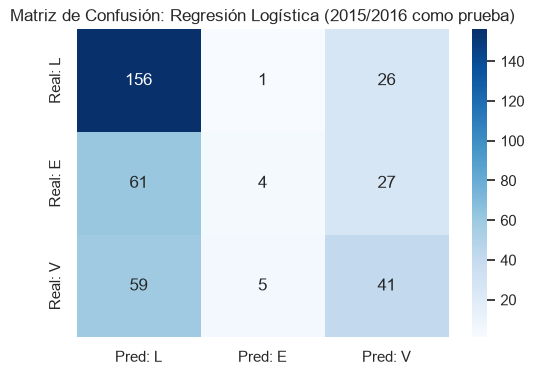

In [105]:
# One-Hot Encoding de los IDs
X_hist = df_historico[['home_team_api_id', 'away_team_api_id']].astype(str)
y_hist = df_historico['Resultado']
X_encoded = pd.get_dummies(X_hist)

# Máscara para separar entrenamiento y prueba (2015/2016 como prueba)
train_mask = df_historico['season'] != '2015/2016'
test_mask = df_historico['season'] == '2015/2016'

X_train_h, y_train_h = X_encoded[train_mask], y_hist[train_mask]
X_test_h, y_test_h = X_encoded[test_mask], y_hist[test_mask]

# Entreno el modelo y mido tiempo y memoria
lr_model = LogisticRegression(max_iter=1000, random_state=42)
tracemalloc.start()
inicio_lr = time.time()
lr_model.fit(X_train_h, y_train_h)
y_pred_lr = lr_model.predict(X_test_h)
_, memoria_max_lr = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_lr = time.time() - inicio_lr
ram_lr_mb = memoria_max_lr / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_lr:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_lr_mb:.4f} MB")
print(f"Accuracy General: {accuracy_score(y_test_h, y_pred_lr) * 100:.2f}%\n")
print("Classification Report (Precisión, Recall, F1-Score):")
print(classification_report(y_test_h, y_pred_lr, zero_division=0))

# Matriz de Confusión
cm = confusion_matrix(y_test_h, y_pred_lr, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred: L', 'Pred: E', 'Pred: V'], yticklabels=['Real: L', 'Real: E', 'Real: V'])
plt.title('Matriz de Confusión: Regresión Logística (2015/2016 como prueba)')
plt.show()

Tiempo de entrenamiento y predicción: 0.0310 segundos
Consumo máximo de memoria: 2.8747 MB
Accuracy Naive Bayes: 47.37%

Classification Report:
              precision    recall  f1-score   support

           E       0.34      0.25      0.29        92
           L       0.63      0.54      0.58       183
           V       0.38      0.56      0.45       105

    accuracy                           0.47       380
   macro avg       0.45      0.45      0.44       380
weighted avg       0.49      0.47      0.47       380



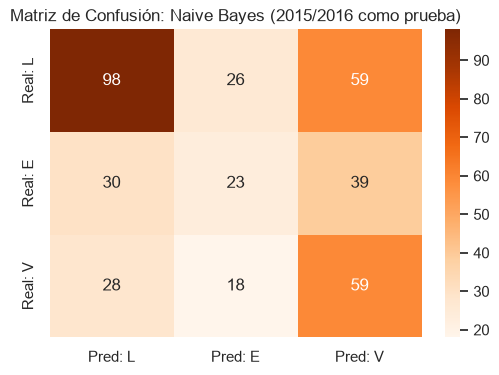

In [106]:
# Entrenamiento de Naive Bayes
nb_model = GaussianNB()
tracemalloc.start()
inicio_nb = time.time()
nb_model.fit(X_train_h.to_numpy(), y_train_h)

# Predigo los resultados de la temporada 2015/2016
y_pred_nb = nb_model.predict(X_test_h.to_numpy())
_, memoria_max_nb = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_nb = time.time() - inicio_nb
ram_nb_mb = memoria_max_nb / (1024 * 1024)

# Muestro las métricas del modelo
print(f"Tiempo de entrenamiento y predicción: {tiempo_nb:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_nb_mb:.4f} MB")
print(f"Accuracy Naive Bayes: {accuracy_score(y_test_h, y_pred_nb) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_h, y_pred_nb, zero_division=0))

# Muestro la matriz de confusión
cm_nb = confusion_matrix(y_test_h, y_pred_nb, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_nb, annot=True, fmt='d', cmap='Oranges',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Matriz de Confusión: Naive Bayes (2015/2016 como prueba)')
plt.show()

Tiempo de entrenamiento y predicción: 0.0710 segundos
Consumo máximo de memoria: 1.4985 MB
Accuracy Árbol de Decisión: 47.37%

Classification Report:
              precision    recall  f1-score   support

           E       0.24      0.21      0.22        92
           L       0.59      0.67      0.63       183
           V       0.41      0.36      0.38       105

    accuracy                           0.47       380
   macro avg       0.41      0.41      0.41       380
weighted avg       0.46      0.47      0.46       380



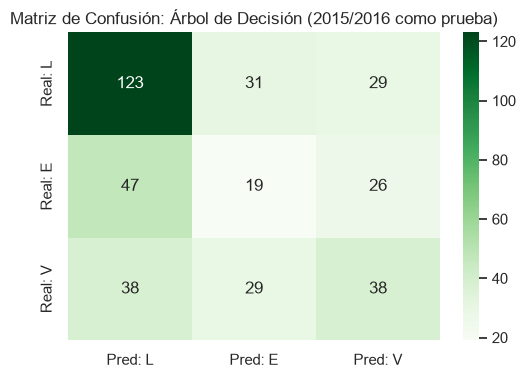

In [107]:
# Entrenamiento de Árbol de Decisión
dt_model = DecisionTreeClassifier(random_state=42)
tracemalloc.start()
inicio_dt = time.time()
dt_model.fit(X_train_h, y_train_h)

# Predigo los resultados de la temporada 2015/2016
y_pred_dt = dt_model.predict(X_test_h)
_, memoria_max_dt = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_dt = time.time() - inicio_dt
ram_dt_mb = memoria_max_dt / (1024 * 1024)

# Muestro las métricas del modelo
print(f"Tiempo de entrenamiento y predicción: {tiempo_dt:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_dt_mb:.4f} MB")
print(f"Accuracy Árbol de Decisión: {accuracy_score(y_test_h, y_pred_dt) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_h, y_pred_dt, zero_division=0))

# Muestro la matriz de confusión
cm_dt = confusion_matrix(y_test_h, y_pred_dt, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_dt, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Matriz de Confusión: Árbol de Decisión (2015/2016 como prueba)')
plt.show()

Tiempo de entrenamiento y predicción: 2.1115 segundos
Consumo máximo de memoria: 1.3547 MB
Accuracy Random Forest: 47.11%

Classification Report:
              precision    recall  f1-score   support

           E       0.24      0.15      0.19        92
           L       0.57      0.67      0.62       183
           V       0.40      0.40      0.40       105

    accuracy                           0.47       380
   macro avg       0.40      0.41      0.40       380
weighted avg       0.44      0.47      0.45       380



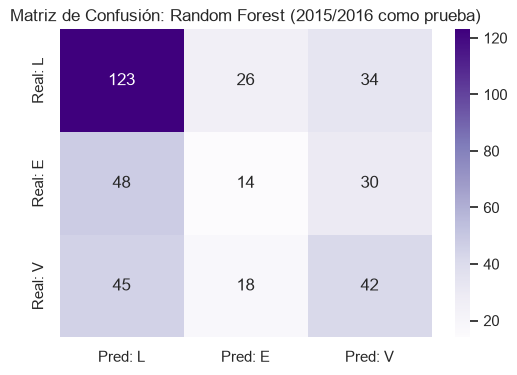

In [108]:
# Entrenamiento de Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
tracemalloc.start()
inicio_rf = time.time()
rf_model.fit(X_train_h, y_train_h)

# Predigo los resultados de la temporada 2015/2016
y_pred_rf = rf_model.predict(X_test_h)
_, memoria_max_rf = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_rf = time.time() - inicio_rf
ram_rf_mb = memoria_max_rf / (1024 * 1024)

# Muestro las métricas del modelo
print(f"Tiempo de entrenamiento y predicción: {tiempo_rf:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_rf_mb:.4f} MB")
print(f"Accuracy Random Forest: {accuracy_score(y_test_h, y_pred_rf) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_h, y_pred_rf, zero_division=0))

# Muestro la matriz de confusión
cm_rf = confusion_matrix(y_test_h, y_pred_rf, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf, annot=True, fmt='d', cmap='Purples',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Matriz de Confusión: Random Forest (2015/2016 como prueba)')
plt.show()

Comparativa de rendimiento de los modelos:


,Modelo,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Reg. Logística,52.89,46.71,42.88,39.01
1,Naive Bayes,47.37,44.91,44.91,43.93
2,Árbol Decisión,47.37,41.35,41.35,41.17
3,Random Forest,47.11,40.24,40.81,40.04


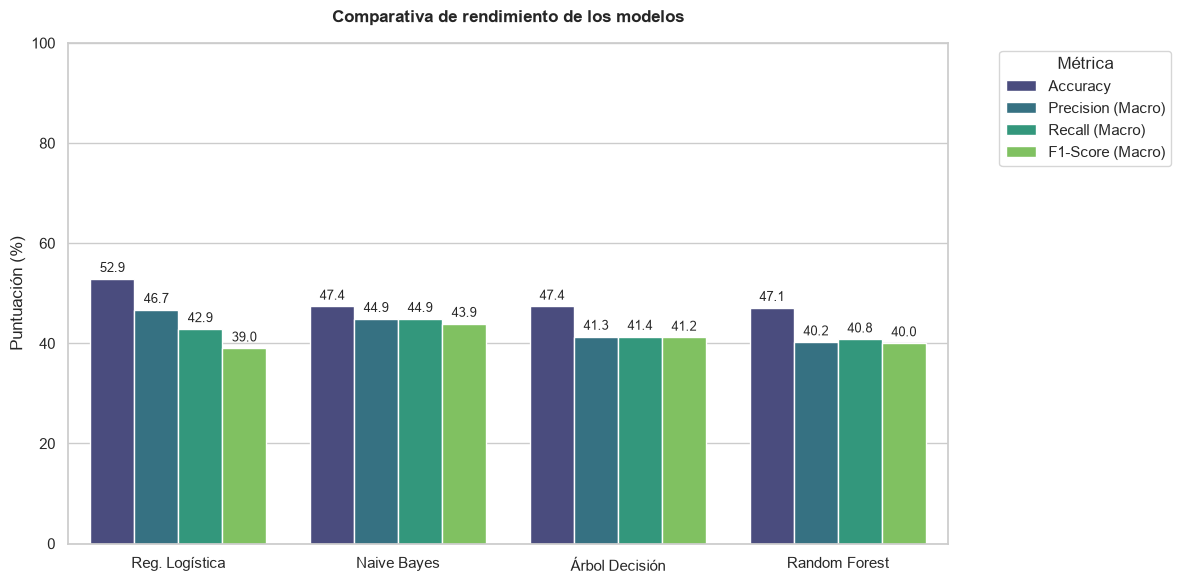

In [109]:
# Comparo las métricas de los cuatro modelos
modelos_labels = ['Reg. Logística', 'Naive Bayes', 'Árbol Decisión', 'Random Forest']
predicciones = [y_pred_lr, y_pred_nb, y_pred_dt, y_pred_rf]

metricas = []
for nombre_modelo, prediccion in zip(modelos_labels, predicciones):
    accuracy = accuracy_score(y_test_h, prediccion)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test_h, prediccion, average='macro', zero_division=0
    )
    metricas.append({
        'Modelo': nombre_modelo,
        'Accuracy': accuracy * 100,
        'Precision (Macro)': precision * 100,
        'Recall (Macro)': recall * 100,
        'F1-Score (Macro)': f1 * 100
    })

df_metricas = pd.DataFrame(metricas)
print("Comparativa de rendimiento de los modelos:")
display(df_metricas.round(2))

# Preparo las métricas para graficarlas
df_melted = df_metricas.melt(
    id_vars='Modelo', var_name='Métrica', value_name='Porcentaje (%)'
 )

# Grafico las métricas de cada modelo
plt.figure(figsize=(12, 6))
sns.set_theme(style='whitegrid')
ax = sns.barplot(
    data=df_melted, x='Modelo', y='Porcentaje (%)',
    hue='Métrica', palette='viridis'
 )
plt.title('Comparativa de rendimiento de los modelos', fontweight='bold', pad=15)
plt.ylabel('Puntuación (%)')
plt.xlabel('')
plt.ylim(0, 100)
plt.legend(title='Métrica', bbox_to_anchor=(1.05, 1), loc='upper left')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

### KNN de posiciones y rating por temporada

`Player_Clean.csv` solo contiene datos biográficos. Para obtener `overall_rating` y `date`, usaré `Player_Attributes_Clean.csv`; para generar las etiquetas de posición, usaré las coordenadas `Y` de `Match_Clean.csv`. Recrearé el flujo del notebook 05 con `MinMaxScaler` y `k=23`, su valor seleccionado. Como el modelo no está guardado para compartirlo entre notebooks, aquí lo volveré a entrenar. Después agruparé los atributos por jugador y temporada para calcular su rating medio y predecir su posición. La temporada se derivará de `date`, considerando julio como inicio.

> **Limitación:** aunque el rating se promedia por temporada, el KNN replica el entrenamiento del notebook 05 con perfiles pico y etiquetas calculadas sobre todo el histórico. Por eso esta tabla es exploratoria, no una evaluación prospectiva libre de fuga temporal.

In [110]:
# Cargo los atributos y partidos para entrenar el KNN de posiciones
df_player_attr = pd.read_csv('../data/processed/clean/Player_Attributes_Clean.csv')
df_match_pos = pd.read_csv('../data/processed/clean/Match_Clean.csv')

# Obtengo las coordenadas Y de los jugadores en partidos
posiciones_lista = []
for lado in ['home', 'away']:
    for numero in range(1, 12):
        df_posicion = df_match_pos[[f'{lado}_player_{numero}', f'{lado}_player_Y{numero}']].copy()
        df_posicion.columns = ['player_api_id', 'y_coord']
        posiciones_lista.append(df_posicion)

df_posiciones = pd.concat(posiciones_lista, ignore_index=True)
df_posiciones = df_posiciones.dropna(subset=['player_api_id', 'y_coord']).copy()

# Clasifico la posición aproximada según la coordenada Y
def clasificar_posicion(y_coord):
    if y_coord == 1.0: return 'GK'
    elif y_coord <= 4.0: return 'DEF'
    elif y_coord <= 8.0: return 'MID'
    return 'FWD'

df_posiciones['position'] = df_posiciones['y_coord'].apply(clasificar_posicion)
df_target_pos = df_posiciones.groupby('player_api_id')['position'].agg(
    lambda posiciones: posiciones.mode().iloc[0]
 ).reset_index()

# Entreno con la versión de mayor rating de cada jugador, como en el notebook 05
df_peak_players = df_player_attr.sort_values(
    by='overall_rating', ascending=False
 ).drop_duplicates(subset=['player_api_id'], keep='first').copy()
df_knn_train = df_peak_players.merge(df_target_pos, on='player_api_id', how='inner')

# Mantengo las mismas variables del clasificador del notebook 05
columnas_excluir_knn = [
    'id', 'player_fifa_api_id', 'player_api_id', 'date',
    'preferred_foot', 'position'
 ]
features_knn = [col for col in df_knn_train.columns if col not in columnas_excluir_knn]
X_knn_train = df_knn_train[features_knn]
y_knn_train = df_knn_train['position']
medianas_knn = X_knn_train.median()
X_knn_train = X_knn_train.fillna(medianas_knn)

scaler_pos = MinMaxScaler()
X_knn_train_scaled = scaler_pos.fit_transform(X_knn_train)
knn_pos = KNeighborsClassifier(n_neighbors=23)
knn_pos.fit(X_knn_train_scaled, y_knn_train)

# Creo la temporada de cada rating; la temporada europea comienza en julio
df_player_attr['date'] = pd.to_datetime(df_player_attr['date'], errors='coerce')
df_player_attr = df_player_attr.dropna(subset=['date']).copy()
año_inicio = df_player_attr['date'].dt.year - (df_player_attr['date'].dt.month < 7).astype(int)
df_player_attr['season'] = año_inicio.astype(str) + '/' + (año_inicio + 1).astype(str)

# Calculo el rating medio y los atributos medios por jugador-temporada
df_jugadores_temporada = df_player_attr.groupby(
    ['player_api_id', 'season'], as_index=False
 )[features_knn].mean()
X_knn_temporada = df_jugadores_temporada[features_knn].fillna(medianas_knn)
X_knn_temporada_scaled = scaler_pos.transform(X_knn_temporada)

# Predigo una posición para el perfil medio de cada temporada
tracemalloc.start()
inicio_knn_pos = time.time()
df_jugadores_temporada['PosicionML'] = knn_pos.predict(X_knn_temporada_scaled)
_, memoria_max_knn_pos = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_knn_pos = time.time() - inicio_knn_pos
ram_knn_pos_mb = memoria_max_knn_pos / (1024 * 1024)
df_jugadores_temporada = df_jugadores_temporada.rename(
    columns={'overall_rating': 'Rating_Temporada'}
 )

print(f"Perfiles jugador-temporada: {len(df_jugadores_temporada)}")
print(f"Tiempo para predecir posiciones: {tiempo_knn_pos:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_knn_pos_mb:.4f} MB")
display(df_jugadores_temporada[
    ['player_api_id', 'season', 'PosicionML', 'Rating_Temporada']
].head())

Perfiles jugador-temporada: 11102
Tiempo para predecir posiciones: 0.1288 segundos
Consumo máximo de memoria: 10.5847 MB


,player_api_id,season,PosicionML,Rating_Temporada
0,2752,2006/2007,DEF,62.0
1,2752,2007/2008,DEF,62.0
2,2752,2008/2009,DEF,65.0
3,2752,2010/2011,DEF,65.0
4,2752,2011/2012,DEF,68.5


In [111]:
# Mapeo de rating medio por jugador y temporada
dict_ratings_temp = df_jugadores_temporada.set_index(
    ['player_api_id', 'season']
 )['Rating_Temporada'].to_dict()
df_calidad = df_jugadores_base.copy().reset_index(drop=True)

# Separo las columnas de jugadores locales y visitantes
cols_home = [f'home_player_{numero}' for numero in range(1, 12)]
cols_away = [f'away_player_{numero}' for numero in range(1, 12)]

# Reemplazo cada ID por el rating medio de ese jugador en esa temporada
for columna in cols_jugadores:
    llaves = pd.Series(
        list(zip(df_calidad[columna], df_calidad['season'])),
        index=df_calidad.index
    )
    df_calidad[columna] = llaves.map(dict_ratings_temp)

print("Ratings por jugador-temporada mapeados.")

# Calculo la mediana de rating disponible para cada equipo en cada partido
df_calidad['Mediana_Local'] = df_calidad[cols_home].median(axis=1)
df_calidad['Mediana_Visitante'] = df_calidad[cols_away].median(axis=1)

# Uso la mediana de temporada como respaldo si faltan todos los ratings de un equipo
medianas_temporada = df_jugadores_temporada.groupby('season')['Rating_Temporada'].median()
mediana_global = df_jugadores_temporada['Rating_Temporada'].median()

for columna in cols_home:
    df_calidad[columna] = (
        df_calidad[columna]
        .fillna(df_calidad['Mediana_Local'])
        .fillna(df_calidad['season'].map(medianas_temporada))
        .fillna(mediana_global)
    )

for columna in cols_away:
    df_calidad[columna] = (
        df_calidad[columna]
        .fillna(df_calidad['Mediana_Visitante'])
        .fillna(df_calidad['season'].map(medianas_temporada))
        .fillna(mediana_global)
    )

# Creo variables de fuerza para cada equipo
df_calidad['Fuerza_Local'] = df_calidad[cols_home].mean(axis=1)
df_calidad['Fuerza_Visitante'] = df_calidad[cols_away].mean(axis=1)
df_calidad['Diferencia_Fuerza'] = df_calidad['Fuerza_Local'] - df_calidad['Fuerza_Visitante']

# Agrego el resultado real del partido
df_calidad['Resultado'] = df_calidad.apply(clasificar_resultado, axis=1)

# Esta media usa toda la temporada; para predecir antes de cada partido debo limitarla por fecha
print(f"Ratings faltantes tras imputación: {df_calidad[cols_jugadores].isna().sum().sum()}")
print("Características de fuerza listas:")
cols_ver = [
    'season', 'home_team_goal', 'away_team_goal',
    'Fuerza_Local', 'Fuerza_Visitante', 'Diferencia_Fuerza', 'Resultado'
 ]
display(df_calidad[cols_ver].head())

Ratings por jugador-temporada mapeados.
Ratings faltantes tras imputación: 0
Características de fuerza listas:


,season,home_team_goal,away_team_goal,Fuerza_Local,Fuerza_Visitante,Diferencia_Fuerza,Resultado
0,2008/2009,3,0,79.636364,75.500000,4.136364,L
1,2008/2009,1,1,70.000000,78.090909,-8.090909,E
2,2008/2009,2,1,73.909091,82.681818,-8.772727,L
3,2008/2009,1,0,70.272727,85.272727,-15.000000,L
4,2008/2009,1,1,73.272727,78.818182,-5.545455,E


In [ ]:
# Reviso la distribución de posiciones predichas
posicion_counts = df_jugadores_temporada['PosicionML'].value_counts(normalize=True) * 100
print("Distribución de posiciones predichas:")
display(posicion_counts.to_frame(name='Porcentaje (%)').round(2))

# Reviso el accuracy del KNN contra la posición más frecuente de cada jugador
df_knn_eval = df_jugadores_temporada.merge(df_target_pos, on='player_api_id', how='inner')
accuracy_knn = accuracy_score(df_knn_eval['position'], df_knn_eval['PosicionML'])
print(f"Accuracy del modelo KNN de posiciones: {accuracy_knn * 100:.2f}%")

### Modelos con identidad y fuerza de plantilla

Combinaré los IDs de los equipos con `Fuerza_Local`, `Fuerza_Visitante` y `Diferencia_Fuerza`. La temporada `2015/2016` queda separada para la prueba final y el escalador se ajusta solo con entrenamiento.

> **Limitación:** las fuerzas se calcularon con el rating medio de toda la temporada. Como ese promedio puede incluir ratings posteriores a un partido, esta prueba es comparativa, no una simulación estricta de predicción antes del encuentro.

In [113]:
# Separo las columnas de identidad y fuerza
cols_equipos = ['home_team_api_id', 'away_team_api_id']
cols_fuerza = ['Fuerza_Local', 'Fuerza_Visitante', 'Diferencia_Fuerza']

# Mantengo 2015/2016 como prueba final
train_mask_hibrido = df_calidad['season'] != '2015/2016'
test_mask_hibrido = df_calidad['season'] == '2015/2016'

# Codifico las identidades usando solo los equipos del entrenamiento
X_equipos_train = pd.get_dummies(
    df_calidad.loc[train_mask_hibrido, cols_equipos].astype(str)
 )
X_equipos_test = pd.get_dummies(
    df_calidad.loc[test_mask_hibrido, cols_equipos].astype(str)
 ).reindex(columns=X_equipos_train.columns, fill_value=0)

# Ajusto el escalador solo con los datos de entrenamiento
scaler_fuerza = MinMaxScaler()
X_fuerza_train = pd.DataFrame(
    scaler_fuerza.fit_transform(df_calidad.loc[train_mask_hibrido, cols_fuerza]),
    columns=cols_fuerza, index=df_calidad.index[train_mask_hibrido]
 )
X_fuerza_test = pd.DataFrame(
    scaler_fuerza.transform(df_calidad.loc[test_mask_hibrido, cols_fuerza]),
    columns=cols_fuerza, index=df_calidad.index[test_mask_hibrido]
 )

# Combino identidad y fuerza en la matriz final
X_train_hibrido = pd.concat([X_equipos_train, X_fuerza_train], axis=1)
X_test_hibrido = pd.concat([X_equipos_test, X_fuerza_test], axis=1)
y_train_hibrido = df_calidad.loc[train_mask_hibrido, 'Resultado']
y_test_hibrido = df_calidad.loc[test_mask_hibrido, 'Resultado']

print(f"Entrenamiento: {X_train_hibrido.shape[0]} partidos, {X_train_hibrido.shape[1]} variables.")
print(f"Prueba 2015/2016: {X_test_hibrido.shape[0]} partidos.")
print(f"Nulos en entrenamiento: {X_train_hibrido.isna().sum().sum()}")
print(f"Nulos en prueba: {X_test_hibrido.isna().sum().sum()}")

Entrenamiento: 2660 partidos, 67 variables.
Prueba 2015/2016: 380 partidos.
Nulos en entrenamiento: 0
Nulos en prueba: 0


Tiempo de entrenamiento y predicción: 0.2302 segundos
Consumo máximo de memoria: 4.3250 MB
Accuracy Regresión Logística: 53.68%

Classification Report:
              precision    recall  f1-score   support

           L       0.58      0.85      0.69       183
           E       0.36      0.04      0.08        92
           V       0.44      0.42      0.43       105

    accuracy                           0.54       380
   macro avg       0.46      0.44      0.40       380
weighted avg       0.49      0.54      0.47       380



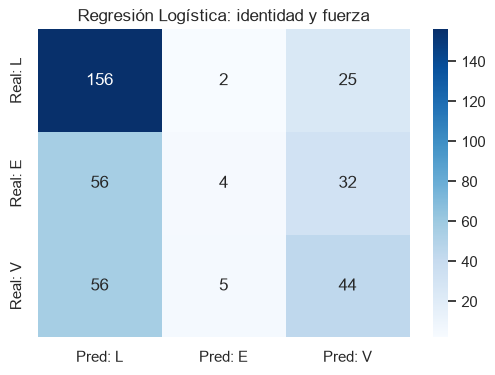

In [114]:
# Regresión Logística con variables híbridas
lr_hibrido = LogisticRegression(max_iter=1000, random_state=42)
tracemalloc.start()
inicio_lr_hibrido = time.time()
lr_hibrido.fit(X_train_hibrido, y_train_hibrido)
y_pred_lr_hibrido = lr_hibrido.predict(X_test_hibrido)
_, memoria_max_lr_hibrido = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_lr_hibrido = time.time() - inicio_lr_hibrido
ram_lr_hibrido_mb = memoria_max_lr_hibrido / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_lr_hibrido:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_lr_hibrido_mb:.4f} MB")
print(f"Accuracy Regresión Logística: {accuracy_score(y_test_hibrido, y_pred_lr_hibrido) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_hibrido, y_pred_lr_hibrido, labels=['L', 'E', 'V'], zero_division=0))

# Matriz de confusión
cm_lr_hibrido = confusion_matrix(y_test_hibrido, y_pred_lr_hibrido, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_lr_hibrido, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Regresión Logística: identidad y fuerza')
plt.show()

Tiempo de entrenamiento y predicción: 0.1101 segundos
Consumo máximo de memoria: 4.4922 MB
Accuracy Naive Bayes: 47.89%

Classification Report:
              precision    recall  f1-score   support

           L       0.64      0.54      0.58       183
           E       0.34      0.25      0.29        92
           V       0.39      0.58      0.46       105

    accuracy                           0.48       380
   macro avg       0.45      0.46      0.44       380
weighted avg       0.50      0.48      0.48       380



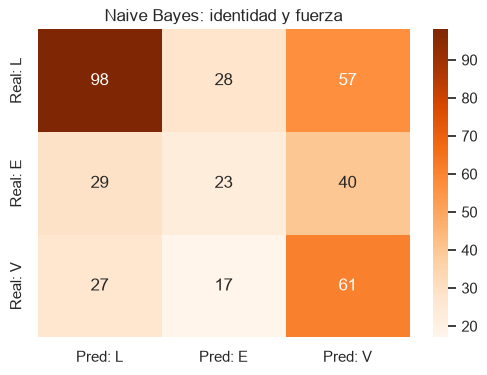

In [115]:
# Naive Bayes con variables híbridas
nb_hibrido = GaussianNB()
tracemalloc.start()
inicio_nb_hibrido = time.time()
nb_hibrido.fit(X_train_hibrido.to_numpy(), y_train_hibrido)
y_pred_nb_hibrido = nb_hibrido.predict(X_test_hibrido.to_numpy())
_, memoria_max_nb_hibrido = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_nb_hibrido = time.time() - inicio_nb_hibrido
ram_nb_hibrido_mb = memoria_max_nb_hibrido / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_nb_hibrido:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_nb_hibrido_mb:.4f} MB")
print(f"Accuracy Naive Bayes: {accuracy_score(y_test_hibrido, y_pred_nb_hibrido) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_hibrido, y_pred_nb_hibrido, labels=['L', 'E', 'V'], zero_division=0))

# Matriz de confusión
cm_nb_hibrido = confusion_matrix(y_test_hibrido, y_pred_nb_hibrido, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_nb_hibrido, annot=True, fmt='d', cmap='Oranges',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Naive Bayes: identidad y fuerza')
plt.show()

Tiempo de entrenamiento y predicción: 0.0597 segundos
Consumo máximo de memoria: 1.3804 MB
Accuracy Árbol de Decisión: 42.89%

Classification Report:
              precision    recall  f1-score   support

           L       0.58      0.58      0.58       183
           E       0.21      0.20      0.20        92
           V       0.36      0.36      0.36       105

    accuracy                           0.43       380
   macro avg       0.38      0.38      0.38       380
weighted avg       0.43      0.43      0.43       380



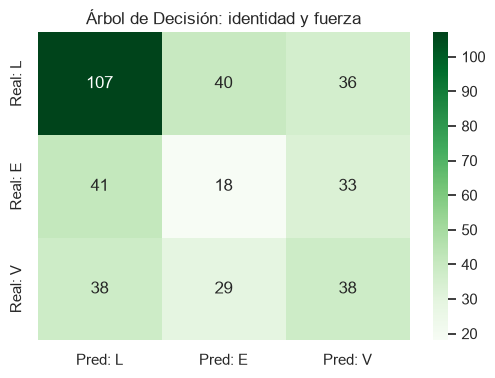

In [116]:
# Árbol de Decisión con variables híbridas
dt_hibrido = DecisionTreeClassifier(random_state=42)
tracemalloc.start()
inicio_dt_hibrido = time.time()
dt_hibrido.fit(X_train_hibrido, y_train_hibrido)
y_pred_dt_hibrido = dt_hibrido.predict(X_test_hibrido)
_, memoria_max_dt_hibrido = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_dt_hibrido = time.time() - inicio_dt_hibrido
ram_dt_hibrido_mb = memoria_max_dt_hibrido / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_dt_hibrido:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_dt_hibrido_mb:.4f} MB")
print(f"Accuracy Árbol de Decisión: {accuracy_score(y_test_hibrido, y_pred_dt_hibrido) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_hibrido, y_pred_dt_hibrido, labels=['L', 'E', 'V'], zero_division=0))

# Matriz de confusión
cm_dt_hibrido = confusion_matrix(y_test_hibrido, y_pred_dt_hibrido, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_dt_hibrido, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Árbol de Decisión: identidad y fuerza')
plt.show()

Tiempo de entrenamiento y predicción: 2.1011 segundos
Consumo máximo de memoria: 1.5166 MB
Accuracy Random Forest: 48.95%

Classification Report:
              precision    recall  f1-score   support

           L       0.57      0.75      0.65       183
           E       0.23      0.12      0.16        92
           V       0.41      0.36      0.38       105

    accuracy                           0.49       380
   macro avg       0.40      0.41      0.40       380
weighted avg       0.44      0.49      0.46       380



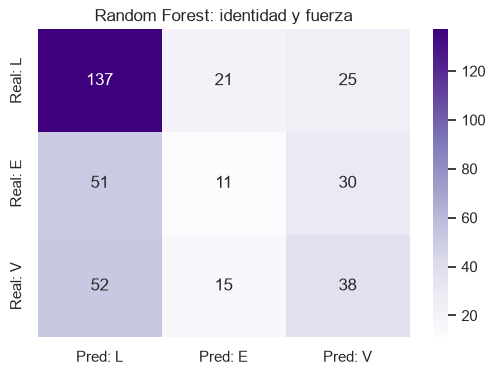

In [117]:
# Random Forest con variables híbridas
rf_hibrido = RandomForestClassifier(n_estimators=100, random_state=42)
tracemalloc.start()
inicio_rf_hibrido = time.time()
rf_hibrido.fit(X_train_hibrido, y_train_hibrido)
y_pred_rf_hibrido = rf_hibrido.predict(X_test_hibrido)
_, memoria_max_rf_hibrido = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_rf_hibrido = time.time() - inicio_rf_hibrido
ram_rf_hibrido_mb = memoria_max_rf_hibrido / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_rf_hibrido:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_rf_hibrido_mb:.4f} MB")
print(f"Accuracy Random Forest: {accuracy_score(y_test_hibrido, y_pred_rf_hibrido) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_hibrido, y_pred_rf_hibrido, labels=['L', 'E', 'V'], zero_division=0))

# Matriz de confusión
cm_rf_hibrido = confusion_matrix(y_test_hibrido, y_pred_rf_hibrido, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf_hibrido, annot=True, fmt='d', cmap='Purples',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Random Forest: identidad y fuerza')
plt.show()

Comparativa de modelos con identidad y fuerza de plantilla:


,Modelo,Accuracy (%),Precision macro (%),Recall macro (%),F1 macro (%),Tiempo (s),Memoria (MB)
0,Reg. Logística,53.68,46.05,43.83,39.89,0.23,4.33
3,Random Forest,48.95,40.45,41.00,39.66,2.10,1.52
1,Naive Bayes,47.89,45.36,45.55,44.43,0.11,4.49
2,Árbol Decisión,42.89,37.91,38.08,37.99,0.06,1.38


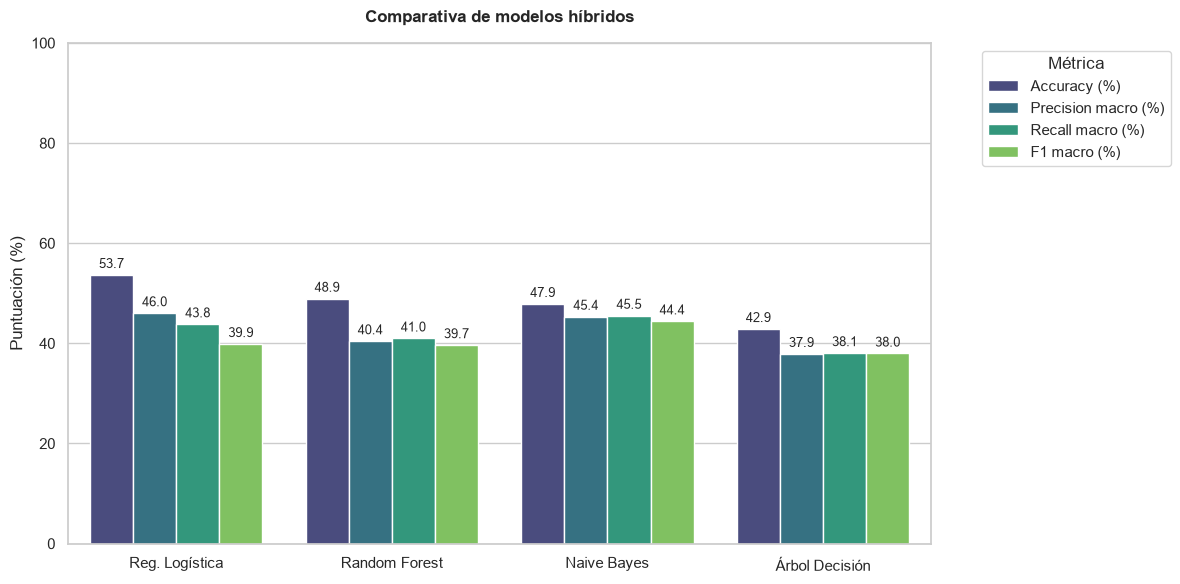

In [118]:
# Comparo las métricas de los modelos híbridos
modelos_hibridos = ['Reg. Logística', 'Naive Bayes', 'Árbol Decisión', 'Random Forest']
predicciones_hibridas = [
    y_pred_lr_hibrido, y_pred_nb_hibrido, y_pred_dt_hibrido, y_pred_rf_hibrido
 ]
tiempos_hibridos = [
    tiempo_lr_hibrido, tiempo_nb_hibrido, tiempo_dt_hibrido, tiempo_rf_hibrido
 ]
memorias_hibridas = [
    ram_lr_hibrido_mb, ram_nb_hibrido_mb, ram_dt_hibrido_mb, ram_rf_hibrido_mb
 ]

metricas_hibridas = []
for nombre_modelo, prediccion, tiempo, memoria in zip(
    modelos_hibridos, predicciones_hibridas, tiempos_hibridos, memorias_hibridas
 ):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test_hibrido, prediccion, average='macro', zero_division=0
    )
    metricas_hibridas.append({
        'Modelo': nombre_modelo,
        'Accuracy (%)': accuracy_score(y_test_hibrido, prediccion) * 100,
        'Precision macro (%)': precision * 100,
        'Recall macro (%)': recall * 100,
        'F1 macro (%)': f1 * 100,
        'Tiempo (s)': tiempo,
        'Memoria (MB)': memoria
    })

df_benchmark_hibrido = pd.DataFrame(metricas_hibridas).sort_values(
    by='Accuracy (%)', ascending=False
 )
print("Comparativa de modelos con identidad y fuerza de plantilla:")
display(df_benchmark_hibrido.round(2))

# Grafico accuracy y métricas macro
df_metricas_hibridas = df_benchmark_hibrido.melt(
    id_vars='Modelo',
    value_vars=['Accuracy (%)', 'Precision macro (%)', 'Recall macro (%)', 'F1 macro (%)'],
    var_name='Métrica',
    value_name='Porcentaje (%)'
 )
plt.figure(figsize=(12, 6))
sns.set_theme(style='whitegrid')
ax = sns.barplot(
    data=df_metricas_hibridas, x='Modelo', y='Porcentaje (%)',
    hue='Métrica', palette='viridis'
 )
plt.title('Comparativa de modelos híbridos', fontweight='bold', pad=15)
plt.ylabel('Puntuación (%)')
plt.xlabel('')
plt.ylim(0, 100)
plt.legend(title='Métrica', bbox_to_anchor=(1.05, 1), loc='upper left')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=9)
plt.tight_layout()
plt.show()

### Forma reciente de los equipos

Para medir la racha de cada equipo, junto sus partidos como local y como visitante en un solo historial, lo ordeno por fecha y sumo los goles a favor y en contra de los cinco partidos anteriores. Uso `shift(1)` para que el partido que voy a predecir no entre en su propia racha.

In [119]:
# Recupero fechas, equipos y goles del dataset original
df_fechas = df_match[
    ['match_api_id', 'date', 'home_team_api_id', 'away_team_api_id',
     'home_team_goal', 'away_team_goal']
].copy()
df_fechas['date'] = pd.to_datetime(df_fechas['date'], errors='coerce')
df_fechas = df_fechas.dropna(subset=['match_api_id', 'date', 'home_team_api_id', 'away_team_api_id'])

# Creo un registro por equipo en cada partido
df_home_hist = df_fechas[
    ['match_api_id', 'date', 'home_team_api_id', 'home_team_goal', 'away_team_goal']
].rename(columns={
    'home_team_api_id': 'team_id',
    'home_team_goal': 'GF',
    'away_team_goal': 'GC'
})
df_away_hist = df_fechas[
    ['match_api_id', 'date', 'away_team_api_id', 'away_team_goal', 'home_team_goal']
].rename(columns={
    'away_team_api_id': 'team_id',
    'away_team_goal': 'GF',
    'home_team_goal': 'GC'
})

# Uno y ordeno el historial por equipo y fecha
df_historial = pd.concat([df_home_hist, df_away_hist], ignore_index=True)
df_historial = df_historial.sort_values(
    ['team_id', 'date', 'match_api_id'], kind='mergesort'
 ).reset_index(drop=True)

# Calculo los goles de los cinco partidos anteriores, sin incluir el actual
for columna in ['GF', 'GC']:
    df_historial[f'{columna}_5'] = df_historial.groupby('team_id')[columna].transform(
        lambda valores: valores.shift(1).rolling(5, min_periods=1).sum()
    ).fillna(0)

# Reemplazo valores anteriores si se vuelve a ejecutar esta celda
columnas_forma = [
    'Local_GF_5', 'Local_GC_5', 'Visita_GF_5', 'Visita_GC_5',
    'Forma_Local', 'Forma_Visitante', 'Diferencia_Forma'
 ]
df_calidad = df_calidad.drop(columns=columnas_forma, errors='ignore')

# Agrego la forma reciente del equipo local
df_calidad = df_calidad.merge(
    df_historial[['match_api_id', 'team_id', 'GF_5', 'GC_5']],
    left_on=['match_api_id', 'home_team_api_id'],
    right_on=['match_api_id', 'team_id'],
    how='left', validate='many_to_one'
 ).rename(columns={'GF_5': 'Local_GF_5', 'GC_5': 'Local_GC_5'}).drop(columns='team_id')

# Agrego la forma reciente del equipo visitante
df_calidad = df_calidad.merge(
    df_historial[['match_api_id', 'team_id', 'GF_5', 'GC_5']],
    left_on=['match_api_id', 'away_team_api_id'],
    right_on=['match_api_id', 'team_id'],
    how='left', validate='many_to_one'
 ).rename(columns={'GF_5': 'Visita_GF_5', 'GC_5': 'Visita_GC_5'}).drop(columns='team_id')

# Si no hay historial previo, la forma inicial es cero
cols_racha = ['Local_GF_5', 'Local_GC_5', 'Visita_GF_5', 'Visita_GC_5']
df_calidad[cols_racha] = df_calidad[cols_racha].fillna(0)

# Calculo la diferencia de goles de los últimos cinco partidos
df_calidad['Forma_Local'] = df_calidad['Local_GF_5'] - df_calidad['Local_GC_5']
df_calidad['Forma_Visitante'] = df_calidad['Visita_GF_5'] - df_calidad['Visita_GC_5']
df_calidad['Diferencia_Forma'] = df_calidad['Forma_Local'] - df_calidad['Forma_Visitante']

print("Forma reciente calculada sin incluir el resultado del partido actual.")
display(df_calidad[
    ['season', 'home_team_api_id', 'away_team_api_id',
     'Forma_Local', 'Forma_Visitante', 'Diferencia_Forma', 'Resultado']
].head(100))

Forma reciente calculada sin incluir el resultado del partido actual.


,season,home_team_api_id,away_team_api_id,Forma_Local,Forma_Visitante,Diferencia_Forma,Resultado
0,2008/2009,10267,8661,0.0,0.0,0.0,L
1,2008/2009,8371,10205,0.0,0.0,0.0,E
2,2008/2009,9783,8633,0.0,0.0,0.0,L
3,2008/2009,8388,8634,0.0,0.0,0.0,L
4,2008/2009,8696,8302,0.0,0.0,0.0,E
...,...,...,...,...,...,...,...
95,2008/2009,8388,8305,-4.0,1.0,-5.0,L
96,2008/2009,8371,8634,0.0,12.0,-12.0,V
97,2008/2009,8661,8633,-9.0,-3.0,-6.0,V
98,2008/2009,10267,10205,-1.0,-2.0,1.0,E


### Integración: identidad, fuerza y forma

En esta integración agrego las rachas de los últimos cinco partidos a las variables de identidad y fuerza de plantilla. Separaré `2015/2016` como prueba final y ajustaré el escalador solo con entrenamiento.

> **Limitación:** `Fuerza_*` usa promedios de rating de toda la temporada, por lo que puede incluir datos posteriores a algunos partidos. La comparación es exploratoria, no una simulación estricta prepartido.

In [120]:
# Separo las columnas de identidad, fuerza y forma
cols_equipos_forma = ['home_team_api_id', 'away_team_api_id']
cols_fuerza_forma = [
    'Fuerza_Local', 'Fuerza_Visitante', 'Diferencia_Fuerza',
    'Forma_Local', 'Forma_Visitante', 'Diferencia_Forma'
 ]

# Mantengo 2015/2016 como prueba final
train_mask_forma = df_calidad['season'] != '2015/2016'
test_mask_forma = df_calidad['season'] == '2015/2016'

# Codifico los equipos con las categorías del entrenamiento
X_equipos_train_forma = pd.get_dummies(
    df_calidad.loc[train_mask_forma, cols_equipos_forma].astype(str)
 )
X_equipos_test_forma = pd.get_dummies(
    df_calidad.loc[test_mask_forma, cols_equipos_forma].astype(str)
 ).reindex(columns=X_equipos_train_forma.columns, fill_value=0)

# Ajusto el escalador solo con los datos de entrenamiento
scaler_forma = MinMaxScaler()
X_numericas_train_forma = pd.DataFrame(
    scaler_forma.fit_transform(df_calidad.loc[train_mask_forma, cols_fuerza_forma]),
    columns=cols_fuerza_forma, index=df_calidad.index[train_mask_forma]
 )
X_numericas_test_forma = pd.DataFrame(
    scaler_forma.transform(df_calidad.loc[test_mask_forma, cols_fuerza_forma]),
    columns=cols_fuerza_forma, index=df_calidad.index[test_mask_forma]
 )

# Combino las variables y separo el target
X_train_forma = pd.concat([X_equipos_train_forma, X_numericas_train_forma], axis=1)
X_test_forma = pd.concat([X_equipos_test_forma, X_numericas_test_forma], axis=1)
y_train_forma = df_calidad.loc[train_mask_forma, 'Resultado']
y_test_forma = df_calidad.loc[test_mask_forma, 'Resultado']

print(f"Entrenamiento: {X_train_forma.shape[0]} partidos, {X_train_forma.shape[1]} variables.")
print(f"Prueba 2015/2016: {X_test_forma.shape[0]} partidos.")
print(f"Nulos en entrenamiento: {X_train_forma.isna().sum().sum()}")
print(f"Nulos en prueba: {X_test_forma.isna().sum().sum()}")

Entrenamiento: 2660 partidos, 70 variables.
Prueba 2015/2016: 380 partidos.
Nulos en entrenamiento: 0
Nulos en prueba: 0


Tiempo de entrenamiento y predicción: 0.2608 segundos
Consumo máximo de memoria: 4.3050 MB
Accuracy Regresión Logística: 54.74%

Classification Report:
              precision    recall  f1-score   support

           L       0.58      0.87      0.70       183
           E       0.46      0.07      0.11        92
           V       0.45      0.41      0.43       105

    accuracy                           0.55       380
   macro avg       0.50      0.45      0.41       380
weighted avg       0.52      0.55      0.48       380



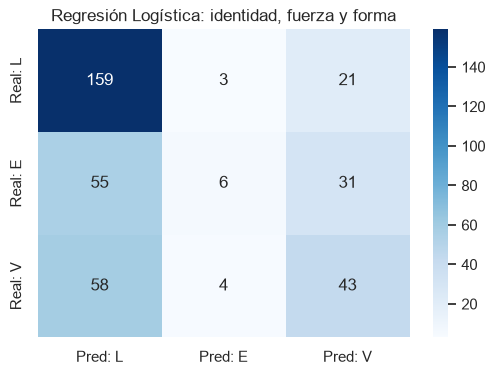

In [121]:
# Regresión Logística con identidad, fuerza y forma
lr_forma = LogisticRegression(max_iter=1000, random_state=42)
tracemalloc.start()
inicio_lr_forma = time.time()
lr_forma.fit(X_train_forma, y_train_forma)
y_pred_lr_forma = lr_forma.predict(X_test_forma)
_, memoria_max_lr_forma = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_lr_forma = time.time() - inicio_lr_forma
ram_lr_forma_mb = memoria_max_lr_forma / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_lr_forma:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_lr_forma_mb:.4f} MB")
print(f"Accuracy Regresión Logística: {accuracy_score(y_test_forma, y_pred_lr_forma) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_forma, y_pred_lr_forma, labels=['L', 'E', 'V'], zero_division=0))

# Matriz de confusión
cm_lr_forma = confusion_matrix(y_test_forma, y_pred_lr_forma, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_lr_forma, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Regresión Logística: identidad, fuerza y forma')
plt.show()

Tiempo de entrenamiento y predicción: 0.1083 segundos
Consumo máximo de memoria: 4.7142 MB
Accuracy Naive Bayes: 47.37%

Classification Report:
              precision    recall  f1-score   support

           L       0.64      0.53      0.58       183
           E       0.33      0.24      0.28        92
           V       0.38      0.58      0.46       105

    accuracy                           0.47       380
   macro avg       0.45      0.45      0.44       380
weighted avg       0.49      0.47      0.47       380



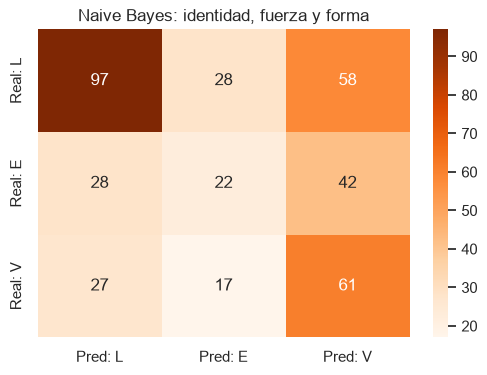

In [122]:
# Naive Bayes con identidad, fuerza y forma
nb_forma = GaussianNB()
tracemalloc.start()
inicio_nb_forma = time.time()
nb_forma.fit(X_train_forma.to_numpy(), y_train_forma)
y_pred_nb_forma = nb_forma.predict(X_test_forma.to_numpy())
_, memoria_max_nb_forma = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_nb_forma = time.time() - inicio_nb_forma
ram_nb_forma_mb = memoria_max_nb_forma / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_nb_forma:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_nb_forma_mb:.4f} MB")
print(f"Accuracy Naive Bayes: {accuracy_score(y_test_forma, y_pred_nb_forma) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_forma, y_pred_nb_forma, labels=['L', 'E', 'V'], zero_division=0))

# Matriz de confusión
cm_nb_forma = confusion_matrix(y_test_forma, y_pred_nb_forma, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_nb_forma, annot=True, fmt='d', cmap='Oranges',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Naive Bayes: identidad, fuerza y forma')
plt.show()

Tiempo de entrenamiento y predicción: 0.0647 segundos
Consumo máximo de memoria: 1.5806 MB
Accuracy Árbol de Decisión: 45.79%

Classification Report:
              precision    recall  f1-score   support

           L       0.58      0.61      0.59       183
           E       0.31      0.30      0.31        92
           V       0.36      0.33      0.35       105

    accuracy                           0.46       380
   macro avg       0.42      0.41      0.41       380
weighted avg       0.45      0.46      0.45       380



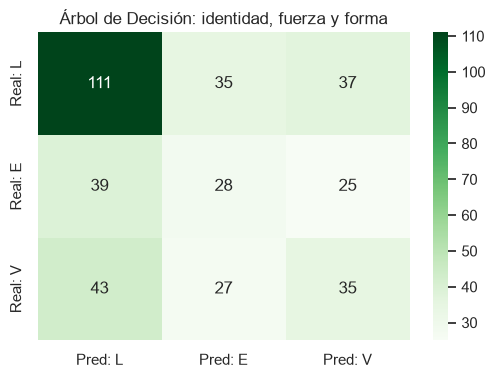

In [123]:
# Árbol de Decisión con identidad, fuerza y forma
dt_forma = DecisionTreeClassifier(random_state=42)
tracemalloc.start()
inicio_dt_forma = time.time()
dt_forma.fit(X_train_forma, y_train_forma)
y_pred_dt_forma = dt_forma.predict(X_test_forma)
_, memoria_max_dt_forma = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_dt_forma = time.time() - inicio_dt_forma
ram_dt_forma_mb = memoria_max_dt_forma / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_dt_forma:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_dt_forma_mb:.4f} MB")
print(f"Accuracy Árbol de Decisión: {accuracy_score(y_test_forma, y_pred_dt_forma) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_forma, y_pred_dt_forma, labels=['L', 'E', 'V'], zero_division=0))

# Matriz de confusión
cm_dt_forma = confusion_matrix(y_test_forma, y_pred_dt_forma, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_dt_forma, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Árbol de Decisión: identidad, fuerza y forma')
plt.show()

Tiempo de entrenamiento y predicción: 2.1330 segundos
Consumo máximo de memoria: 1.5777 MB
Accuracy Random Forest: 52.89%

Classification Report:
              precision    recall  f1-score   support

           L       0.56      0.84      0.67       183
           E       0.33      0.09      0.14        92
           V       0.48      0.38      0.42       105

    accuracy                           0.53       380
   macro avg       0.46      0.43      0.41       380
weighted avg       0.48      0.53      0.47       380



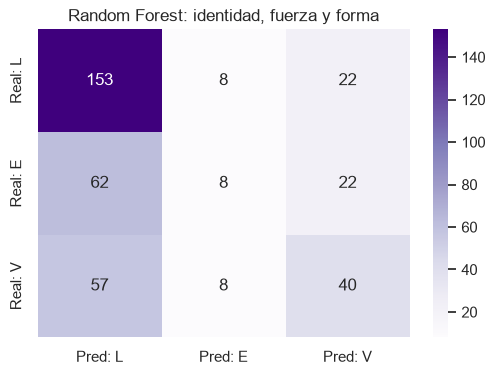

In [124]:
# Random Forest con identidad, fuerza y forma
rf_forma = RandomForestClassifier(n_estimators=100, random_state=42)
tracemalloc.start()
inicio_rf_forma = time.time()
rf_forma.fit(X_train_forma, y_train_forma)
y_pred_rf_forma = rf_forma.predict(X_test_forma)
_, memoria_max_rf_forma = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_rf_forma = time.time() - inicio_rf_forma
ram_rf_forma_mb = memoria_max_rf_forma / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_rf_forma:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_rf_forma_mb:.4f} MB")
print(f"Accuracy Random Forest: {accuracy_score(y_test_forma, y_pred_rf_forma) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_forma, y_pred_rf_forma, labels=['L', 'E', 'V'], zero_division=0))

# Matriz de confusión
cm_rf_forma = confusion_matrix(y_test_forma, y_pred_rf_forma, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf_forma, annot=True, fmt='d', cmap='Purples',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Random Forest: identidad, fuerza y forma')
plt.show()

Comparativa de modelos con identidad, fuerza y forma:


,Modelo,Accuracy (%),Precision macro (%),Recall macro (%),F1 macro (%),Tiempo (s),Memoria (MB)
0,Reg. Logística,54.74,49.96,44.79,41.44,0.26,4.31
3,Random Forest,52.89,45.73,43.47,41.12,2.13,1.58
1,Naive Bayes,47.37,44.85,45.00,43.82,0.11,4.71
2,Árbol Decisión,45.79,41.57,41.47,41.49,0.06,1.58


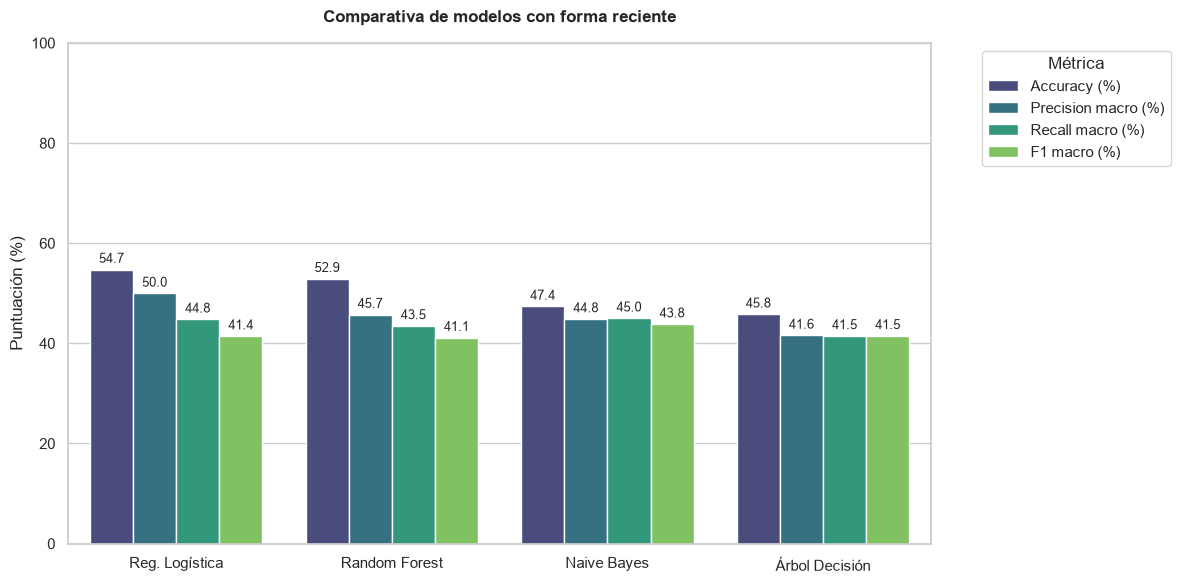

In [125]:
# Comparo los modelos con identidad, fuerza y forma
modelos_forma = ['Reg. Logística', 'Naive Bayes', 'Árbol Decisión', 'Random Forest']
predicciones_forma = [
    y_pred_lr_forma, y_pred_nb_forma, y_pred_dt_forma, y_pred_rf_forma
 ]
tiempos_forma = [
    tiempo_lr_forma, tiempo_nb_forma, tiempo_dt_forma, tiempo_rf_forma
 ]
memorias_forma = [
    ram_lr_forma_mb, ram_nb_forma_mb, ram_dt_forma_mb, ram_rf_forma_mb
 ]

metricas_forma = []
for nombre_modelo, prediccion, tiempo, memoria in zip(
    modelos_forma, predicciones_forma, tiempos_forma, memorias_forma
 ):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test_forma, prediccion, average='macro', zero_division=0
    )
    metricas_forma.append({
        'Modelo': nombre_modelo,
        'Accuracy (%)': accuracy_score(y_test_forma, prediccion) * 100,
        'Precision macro (%)': precision * 100,
        'Recall macro (%)': recall * 100,
        'F1 macro (%)': f1 * 100,
        'Tiempo (s)': tiempo,
        'Memoria (MB)': memoria
    })

df_benchmark_forma = pd.DataFrame(metricas_forma).sort_values(
    by='Accuracy (%)', ascending=False
 )
print("Comparativa de modelos con identidad, fuerza y forma:")
display(df_benchmark_forma.round(2))

# Grafico accuracy y métricas macro
df_metricas_forma = df_benchmark_forma.melt(
    id_vars='Modelo',
    value_vars=['Accuracy (%)', 'Precision macro (%)', 'Recall macro (%)', 'F1 macro (%)'],
    var_name='Métrica',
    value_name='Porcentaje (%)'
 )
plt.figure(figsize=(12, 6))
sns.set_theme(style='whitegrid')
ax = sns.barplot(
    data=df_metricas_forma, x='Modelo', y='Porcentaje (%)',
    hue='Métrica', palette='viridis'
 )
plt.title('Comparativa de modelos con forma reciente', fontweight='bold', pad=15)
plt.ylabel('Puntuación (%)')
plt.xlabel('')
plt.ylim(0, 100)
plt.legend(title='Métrica', bbox_to_anchor=(1.05, 1), loc='upper left')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=9)
plt.tight_layout()
plt.show()

### Integración de cualidades tácticas

Agruparé las tácticas por equipo y año y las cruzaré con la matriz de partidos para crear variables locales, visitantes y sus diferenciales.

> **Limitación:** el cruce por año no garantiza que la actualización táctica ya estuviera disponible antes de cada partido. Por ahora esta integración es exploratoria.

In [126]:
df_tacticas = pd.read_csv('../data/processed/clean/Team_Attributes_Clean.csv')

cols_tacticas = [
    'buildUpPlaySpeed', 'buildUpPlayPassing',
    'chanceCreationShooting', 'defencePressure', 'defenceAggression'
 ]
df_tacticas_agrupado = df_tacticas.groupby(
    ['team_api_id', 'año'], as_index=False
 )[cols_tacticas].mean()

print(f"Perfiles tácticos por equipo y año: {len(df_tacticas_agrupado)}")

# Añado año y liga desde los datos de partidos si todavía no están en df_calidad
columnas_contexto = [
    columna for columna in ['año', 'league_id']
    if columna not in df_calidad.columns
 ]
if columnas_contexto:
    df_calidad = df_calidad.merge(
        df_match[['match_api_id'] + columnas_contexto].drop_duplicates('match_api_id'),
        on='match_api_id', how='left', validate='many_to_one'
    )

# Quito columnas anteriores para poder volver a ejecutar esta integración
cols_tacticas_loc = [
    'Local_Velocidad', 'Local_Pase', 'Local_Tiro', 'Local_Presion', 'Local_Agresividad'
 ]
cols_tacticas_vis = [
    'Visita_Velocidad', 'Visita_Pase', 'Visita_Tiro', 'Visita_Presion', 'Visita_Agresividad'
 ]
cols_diferenciales_tacticos = ['Dif_Presion', 'Dif_Velocidad', 'Dif_Agresividad']
df_calidad = df_calidad.drop(
    columns=cols_tacticas_loc + cols_tacticas_vis + cols_diferenciales_tacticos,
    errors='ignore'
 )

print("\nIntegro las tácticas locales y visitantes")
df_calidad = df_calidad.merge(
    df_tacticas_agrupado,
    left_on=['home_team_api_id', 'año'],
    right_on=['team_api_id', 'año'],
    how='left', validate='many_to_one'
 ).rename(columns={
    'buildUpPlaySpeed': 'Local_Velocidad',
    'buildUpPlayPassing': 'Local_Pase',
    'chanceCreationShooting': 'Local_Tiro',
    'defencePressure': 'Local_Presion',
    'defenceAggression': 'Local_Agresividad'
 }).drop(columns='team_api_id')

df_calidad = df_calidad.merge(
    df_tacticas_agrupado,
    left_on=['away_team_api_id', 'año'],
    right_on=['team_api_id', 'año'],
    how='left', validate='many_to_one'
 ).rename(columns={
    'buildUpPlaySpeed': 'Visita_Velocidad',
    'buildUpPlayPassing': 'Visita_Pase',
    'chanceCreationShooting': 'Visita_Tiro',
    'defencePressure': 'Visita_Presion',
    'defenceAggression': 'Visita_Agresividad'
 }).drop(columns='team_api_id')

# Imputo los faltantes con la mediana de la misma liga y año
for columna in cols_tacticas_loc + cols_tacticas_vis:
    mediana_liga_año = df_calidad.groupby(['league_id', 'año'])[columna].transform('median')
    df_calidad[columna] = df_calidad[columna].fillna(mediana_liga_año)
    df_calidad[columna] = df_calidad[columna].fillna(df_calidad[columna].median())

print("Tácticas integradas.")

# Calculo diferenciales entre local y visitante
df_calidad['Dif_Presion'] = df_calidad['Local_Presion'] - df_calidad['Visita_Presion']
df_calidad['Dif_Velocidad'] = df_calidad['Local_Velocidad'] - df_calidad['Visita_Velocidad']
df_calidad['Dif_Agresividad'] = df_calidad['Local_Agresividad'] - df_calidad['Visita_Agresividad']

cols_vista_tacticas = [
    'season', 'home_team_api_id', 'away_team_api_id',
    'Local_Presion', 'Visita_Presion', 'Dif_Presion',
    'Local_Velocidad', 'Visita_Velocidad', 'Dif_Velocidad',
    'Dif_Agresividad'
 ]
print(f"Nulos en las variables tácticas: {df_calidad[cols_tacticas_loc + cols_tacticas_vis].isna().sum().sum()}")
display(df_calidad[cols_vista_tacticas].head())

Perfiles tácticos por equipo y año: 187

Integro las tácticas locales y visitantes
Tácticas integradas.
Nulos en las variables tácticas: 0


,season,home_team_api_id,away_team_api_id,Local_Presion,Visita_Presion,Dif_Presion,Local_Velocidad,Visita_Velocidad,Dif_Velocidad,Dif_Agresividad
0,2008/2009,10267,8661,49.0,49.0,0.0,50.0,50.0,0.0,0.0
1,2008/2009,8371,10205,49.0,49.0,0.0,50.0,50.0,0.0,0.0
2,2008/2009,9783,8633,49.0,49.0,0.0,50.0,50.0,0.0,0.0
3,2008/2009,8388,8634,49.0,49.0,0.0,50.0,50.0,0.0,0.0
4,2008/2009,8696,8302,49.0,49.0,0.0,50.0,50.0,0.0,0.0


In [127]:
# Preparo las variables de identidad, fuerza, forma y táctica
cols_equipos_def = ['home_team_api_id', 'away_team_api_id']
cols_continuas_def = [
    'Fuerza_Local', 'Fuerza_Visitante', 'Diferencia_Fuerza',
    'Forma_Local', 'Forma_Visitante', 'Diferencia_Forma',
    'Local_Velocidad', 'Local_Pase', 'Local_Tiro', 'Local_Presion', 'Local_Agresividad',
    'Visita_Velocidad', 'Visita_Pase', 'Visita_Tiro', 'Visita_Presion', 'Visita_Agresividad',
    'Dif_Presion', 'Dif_Velocidad', 'Dif_Agresividad'
 ]

# Separo 2015/2016 como prueba final antes de ajustar transformaciones
train_mask_def = df_calidad['season'] != '2015/2016'
test_mask_def = df_calidad['season'] == '2015/2016'

# Codifico los IDs de equipo usando las categorías del entrenamiento
X_eq_train = pd.get_dummies(
    df_calidad.loc[train_mask_def, cols_equipos_def].astype(str)
 )
X_eq_test = pd.get_dummies(
    df_calidad.loc[test_mask_def, cols_equipos_def].astype(str)
 ).reindex(columns=X_eq_train.columns, fill_value=0)

# Ajusto el escalador solo con las métricas del entrenamiento
scaler_def = MinMaxScaler()
X_cont_train = pd.DataFrame(
    scaler_def.fit_transform(df_calidad.loc[train_mask_def, cols_continuas_def]),
    columns=cols_continuas_def, index=df_calidad.index[train_mask_def]
 )
X_cont_test = pd.DataFrame(
    scaler_def.transform(df_calidad.loc[test_mask_def, cols_continuas_def]),
    columns=cols_continuas_def, index=df_calidad.index[test_mask_def]
 )

# Combino las variables y separo el resultado
X_train_def = pd.concat([X_eq_train, X_cont_train], axis=1)
X_test_def = pd.concat([X_eq_test, X_cont_test], axis=1)
y_train_def = df_calidad.loc[train_mask_def, 'Resultado']
y_test_def = df_calidad.loc[test_mask_def, 'Resultado']

print(f"Entrenamiento: {X_train_def.shape[0]} partidos, {X_train_def.shape[1]} variables.")
print(f"Prueba 2015/2016: {X_test_def.shape[0]} partidos.")
print(f"Nulos en entrenamiento: {X_train_def.isna().sum().sum()}")
print(f"Nulos en prueba: {X_test_def.isna().sum().sum()}")

Entrenamiento: 2660 partidos, 83 variables.
Prueba 2015/2016: 380 partidos.
Nulos en entrenamiento: 0
Nulos en prueba: 0


### Benchmark definitivo: identidad, fuerza, forma y táctica

Comparo los cuatro clasificadores con identidad de equipos y variables continuas de fuerza, racha reciente y estilo táctico. Mantengo `2015/2016` como prueba final y ajusto el escalador solo con temporadas anteriores.

> **Limitación:** la fuerza se calcula con ratings medios de toda la temporada y las tácticas se agrupan por año. Estas variables pueden contener información que no estaba disponible antes de algunos partidos, así que las métricas son exploratorias, no una evaluación estricta prepartido.

Tiempo de entrenamiento y predicción: 0.3016 segundos
Consumo máximo de memoria: 4.8368 MB
Accuracy Regresión Logística: 53.42%

Classification Report:
              precision    recall  f1-score   support

           L       0.57      0.86      0.69       183
           E       0.29      0.05      0.09        92
           V       0.46      0.38      0.42       105

    accuracy                           0.53       380
   macro avg       0.44      0.43      0.40       380
weighted avg       0.47      0.53      0.47       380



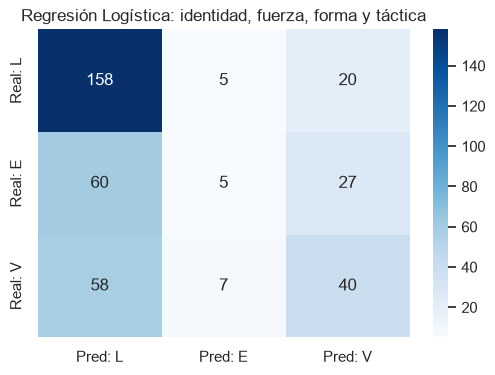

In [128]:
# Regresión Logística con variables definitivas
lr_def = LogisticRegression(max_iter=1000, random_state=42)
tracemalloc.start()
inicio_lr_def = time.time()
lr_def.fit(X_train_def, y_train_def)
y_pred_lr_def = lr_def.predict(X_test_def)
_, memoria_max_lr_def = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_lr_def = time.time() - inicio_lr_def
ram_lr_def_mb = memoria_max_lr_def / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_lr_def:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_lr_def_mb:.4f} MB")
print(f"Accuracy Regresión Logística: {accuracy_score(y_test_def, y_pred_lr_def) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_def, y_pred_lr_def, labels=['L', 'E', 'V'], zero_division=0))

# Matriz de confusión
cm_lr_def = confusion_matrix(y_test_def, y_pred_lr_def, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_lr_def, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Regresión Logística: identidad, fuerza, forma y táctica')
plt.show()

Tiempo de entrenamiento y predicción: 0.1458 segundos
Consumo máximo de memoria: 6.4395 MB
Accuracy Naive Bayes: 46.58%

Classification Report:
              precision    recall  f1-score   support

           L       0.64      0.52      0.57       183
           E       0.31      0.24      0.27        92
           V       0.37      0.56      0.45       105

    accuracy                           0.47       380
   macro avg       0.44      0.44      0.43       380
weighted avg       0.48      0.47      0.47       380



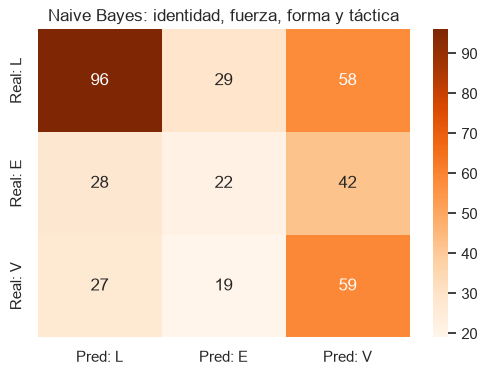

In [129]:
# Naive Bayes con variables definitivas
nb_def = GaussianNB()
tracemalloc.start()
inicio_nb_def = time.time()
nb_def.fit(X_train_def.to_numpy(), y_train_def)
y_pred_nb_def = nb_def.predict(X_test_def.to_numpy())
_, memoria_max_nb_def = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_nb_def = time.time() - inicio_nb_def
ram_nb_def_mb = memoria_max_nb_def / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_nb_def:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_nb_def_mb:.4f} MB")
print(f"Accuracy Naive Bayes: {accuracy_score(y_test_def, y_pred_nb_def) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_def, y_pred_nb_def, labels=['L', 'E', 'V'], zero_division=0))

# Matriz de confusión
cm_nb_def = confusion_matrix(y_test_def, y_pred_nb_def, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_nb_def, annot=True, fmt='d', cmap='Oranges',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Naive Bayes: identidad, fuerza, forma y táctica')
plt.show()

Tiempo de entrenamiento y predicción: 0.0799 segundos
Consumo máximo de memoria: 1.7049 MB
Accuracy Árbol de Decisión: 47.37%

Classification Report:
              precision    recall  f1-score   support

           L       0.59      0.59      0.59       183
           E       0.33      0.29      0.31        92
           V       0.39      0.43      0.41       105

    accuracy                           0.47       380
   macro avg       0.44      0.44      0.44       380
weighted avg       0.47      0.47      0.47       380



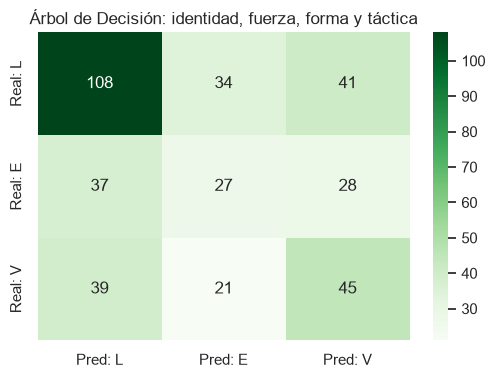

In [130]:
# Árbol de Decisión con variables definitivas
dt_def = DecisionTreeClassifier(random_state=42)
tracemalloc.start()
inicio_dt_def = time.time()
dt_def.fit(X_train_def, y_train_def)
y_pred_dt_def = dt_def.predict(X_test_def)
_, memoria_max_dt_def = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_dt_def = time.time() - inicio_dt_def
ram_dt_def_mb = memoria_max_dt_def / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_dt_def:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_dt_def_mb:.4f} MB")
print(f"Accuracy Árbol de Decisión: {accuracy_score(y_test_def, y_pred_dt_def) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_def, y_pred_dt_def, labels=['L', 'E', 'V'], zero_division=0))

# Matriz de confusión
cm_dt_def = confusion_matrix(y_test_def, y_pred_dt_def, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_dt_def, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Árbol de Decisión: identidad, fuerza, forma y táctica')
plt.show()

Tiempo de entrenamiento y predicción: 2.2222 segundos
Consumo máximo de memoria: 1.7025 MB
Accuracy Random Forest: 51.84%

Classification Report:
              precision    recall  f1-score   support

           L       0.56      0.81      0.66       183
           E       0.14      0.04      0.07        92
           V       0.52      0.43      0.47       105

    accuracy                           0.52       380
   macro avg       0.41      0.43      0.40       380
weighted avg       0.45      0.52      0.46       380



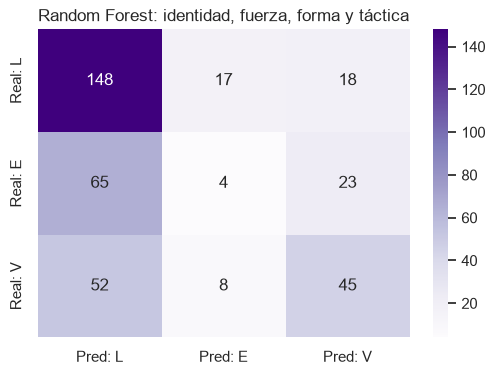

In [131]:
# Random Forest con variables definitivas
rf_def = RandomForestClassifier(n_estimators=100, random_state=42)
tracemalloc.start()
inicio_rf_def = time.time()
rf_def.fit(X_train_def, y_train_def)
y_pred_rf_def = rf_def.predict(X_test_def)
_, memoria_max_rf_def = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_rf_def = time.time() - inicio_rf_def
ram_rf_def_mb = memoria_max_rf_def / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_rf_def:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_rf_def_mb:.4f} MB")
print(f"Accuracy Random Forest: {accuracy_score(y_test_def, y_pred_rf_def) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_def, y_pred_rf_def, labels=['L', 'E', 'V'], zero_division=0))

# Matriz de confusión
cm_rf_def = confusion_matrix(y_test_def, y_pred_rf_def, labels=['L', 'E', 'V'])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf_def, annot=True, fmt='d', cmap='Purples',
    xticklabels=['Pred: L', 'Pred: E', 'Pred: V'],
    yticklabels=['Real: L', 'Real: E', 'Real: V']
 )
plt.title('Random Forest: identidad, fuerza, forma y táctica')
plt.show()

Comparativa definitiva: identidad, fuerza, forma y táctica


,Modelo,Accuracy (%),Precision macro (%),Recall macro (%),F1 macro (%),Tiempo (s),Memoria (MB)
0,Reg. Logística,53.42,44.21,43.29,39.90,0.30,4.84
3,Random Forest,51.84,40.66,42.69,39.93,2.22,1.70
2,Árbol Decisión,47.37,43.70,43.74,43.66,0.08,1.70
1,Naive Bayes,46.58,44.04,44.19,43.11,0.15,6.44


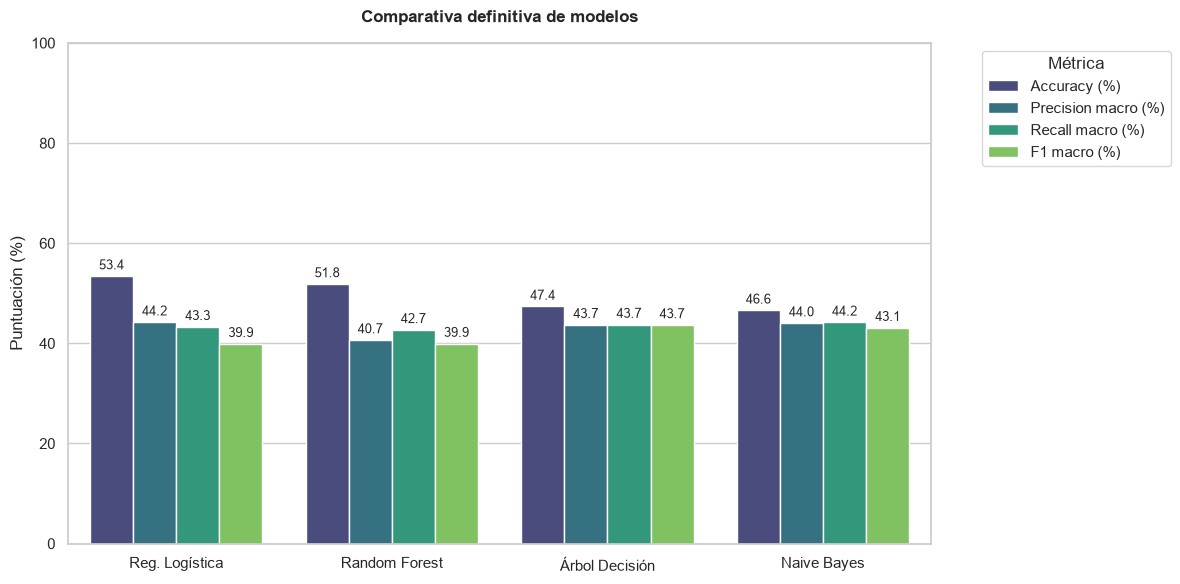

In [132]:
# Comparo los cuatro modelos con todas las variables definitivas
modelos_def = ['Reg. Logística', 'Naive Bayes', 'Árbol Decisión', 'Random Forest']
predicciones_def = [
    y_pred_lr_def, y_pred_nb_def, y_pred_dt_def, y_pred_rf_def
 ]
tiempos_def = [tiempo_lr_def, tiempo_nb_def, tiempo_dt_def, tiempo_rf_def]
memorias_def = [ram_lr_def_mb, ram_nb_def_mb, ram_dt_def_mb, ram_rf_def_mb]

metricas_def = []
for nombre_modelo, prediccion, tiempo, memoria in zip(
    modelos_def, predicciones_def, tiempos_def, memorias_def
 ):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test_def, prediccion, average='macro', zero_division=0
    )
    metricas_def.append({
        'Modelo': nombre_modelo,
        'Accuracy (%)': accuracy_score(y_test_def, prediccion) * 100,
        'Precision macro (%)': precision * 100,
        'Recall macro (%)': recall * 100,
        'F1 macro (%)': f1 * 100,
        'Tiempo (s)': tiempo,
        'Memoria (MB)': memoria
    })

df_resultados_def = pd.DataFrame(metricas_def).sort_values(
    by='Accuracy (%)', ascending=False
 )
print("Comparativa definitiva: identidad, fuerza, forma y táctica")
display(df_resultados_def.round(2))

# Grafico accuracy y métricas macro
df_metricas_def = df_resultados_def.melt(
    id_vars='Modelo',
    value_vars=['Accuracy (%)', 'Precision macro (%)', 'Recall macro (%)', 'F1 macro (%)'],
    var_name='Métrica',
    value_name='Porcentaje (%)'
 )
plt.figure(figsize=(12, 6))
sns.set_theme(style='whitegrid')
ax = sns.barplot(
    data=df_metricas_def, x='Modelo', y='Porcentaje (%)',
    hue='Métrica', palette='viridis'
 )
plt.title('Comparativa definitiva de modelos', fontweight='bold', pad=15)
plt.ylabel('Puntuación (%)')
plt.xlabel('')
plt.ylim(0, 100)
plt.legend(title='Métrica', bbox_to_anchor=(1.05, 1), loc='upper left')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=9)
plt.tight_layout()
plt.show()

### Enfoque binario: gana local o no gana local

El empate es la clase más difícil de predecir, así que simplifico el problema a dos clases: `1` si gana el local y `0` si empata o gana el visitante. Reutilizo la matriz definitiva (`X_train_def` y `X_test_def`) y comparo de nuevo los cuatro modelos.

Distribución binaria en entrenamiento:


Resultado
0    51.05
1    48.95
Name: proportion, dtype: float64

Tiempo de entrenamiento y predicción: 0.0648 segundos
Consumo máximo de memoria: 4.8239 MB
Accuracy binaria: 66.05%

Classification Report:
                   precision    recall  f1-score   support

No Gana Local (0)       0.67      0.67      0.67       197
   Gana Local (1)       0.65      0.65      0.65       183

         accuracy                           0.66       380
        macro avg       0.66      0.66      0.66       380
     weighted avg       0.66      0.66      0.66       380



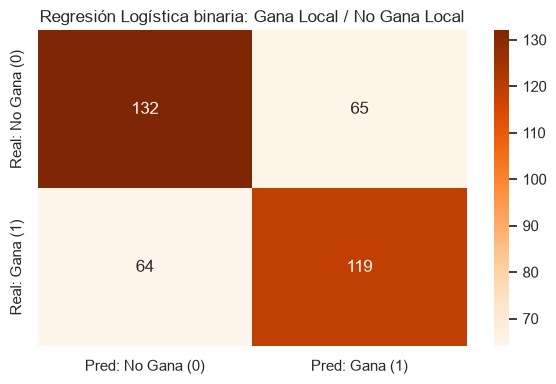

In [133]:
# Convierto el resultado a: gana local (1) o no gana local (0)
y_train_binario = (y_train_def == 'L').astype(int)
y_test_binario = (y_test_def == 'L').astype(int)

print("Distribución binaria en entrenamiento:")
display((y_train_binario.value_counts(normalize=True).sort_index() * 100).round(2))

# Entreno Regresión Logística para la clasificación binaria
lr_binario = LogisticRegression(max_iter=1000, random_state=42)
tracemalloc.start()
inicio_lr_binario = time.time()
lr_binario.fit(X_train_def, y_train_binario)
y_pred_binario = lr_binario.predict(X_test_def)
_, memoria_max_lr_binario = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_lr_binario = time.time() - inicio_lr_binario
ram_lr_binario_mb = memoria_max_lr_binario / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_lr_binario:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_lr_binario_mb:.4f} MB")
print(f"Accuracy binaria: {accuracy_score(y_test_binario, y_pred_binario) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(
    y_test_binario, y_pred_binario, labels=[0, 1],
    target_names=['No Gana Local (0)', 'Gana Local (1)'], zero_division=0
))

# Matriz de confusión
cm_binario = confusion_matrix(y_test_binario, y_pred_binario, labels=[0, 1])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_binario, annot=True, fmt='d', cmap='Oranges',
    xticklabels=['Pred: No Gana (0)', 'Pred: Gana (1)'],
    yticklabels=['Real: No Gana (0)', 'Real: Gana (1)']
 )
plt.title('Regresión Logística binaria: Gana Local / No Gana Local')
plt.tight_layout()
plt.show()

Tiempo de entrenamiento y predicción: 0.1468 segundos
Consumo máximo de memoria: 6.4616 MB
Accuracy Naive Bayes binario: 62.89%

Classification Report:
                   precision    recall  f1-score   support

No Gana Local (0)       0.65      0.62      0.64       197
   Gana Local (1)       0.61      0.63      0.62       183

         accuracy                           0.63       380
        macro avg       0.63      0.63      0.63       380
     weighted avg       0.63      0.63      0.63       380



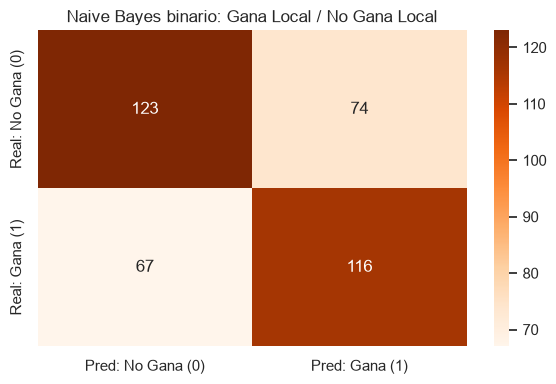

In [134]:
# Naive Bayes para gana local o no gana local
nb_binario = GaussianNB()
tracemalloc.start()
inicio_nb_binario = time.time()
nb_binario.fit(X_train_def.to_numpy(), y_train_binario)
y_pred_nb_binario = nb_binario.predict(X_test_def.to_numpy())
_, memoria_max_nb_binario = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_nb_binario = time.time() - inicio_nb_binario
ram_nb_binario_mb = memoria_max_nb_binario / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_nb_binario:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_nb_binario_mb:.4f} MB")
print(f"Accuracy Naive Bayes binario: {accuracy_score(y_test_binario, y_pred_nb_binario) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(
    y_test_binario, y_pred_nb_binario, labels=[0, 1],
    target_names=['No Gana Local (0)', 'Gana Local (1)'], zero_division=0
))

# Matriz de confusión
cm_nb_binario = confusion_matrix(y_test_binario, y_pred_nb_binario, labels=[0, 1])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_nb_binario, annot=True, fmt='d', cmap='Oranges',
    xticklabels=['Pred: No Gana (0)', 'Pred: Gana (1)'],
    yticklabels=['Real: No Gana (0)', 'Real: Gana (1)']
 )
plt.title('Naive Bayes binario: Gana Local / No Gana Local')
plt.tight_layout()
plt.show()

Tiempo de entrenamiento y predicción: 0.0833 segundos
Consumo máximo de memoria: 1.8455 MB
Accuracy Árbol de Decisión binario: 60.00%

Classification Report:
                   precision    recall  f1-score   support

No Gana Local (0)       0.61      0.65      0.63       197
   Gana Local (1)       0.59      0.55      0.57       183

         accuracy                           0.60       380
        macro avg       0.60      0.60      0.60       380
     weighted avg       0.60      0.60      0.60       380



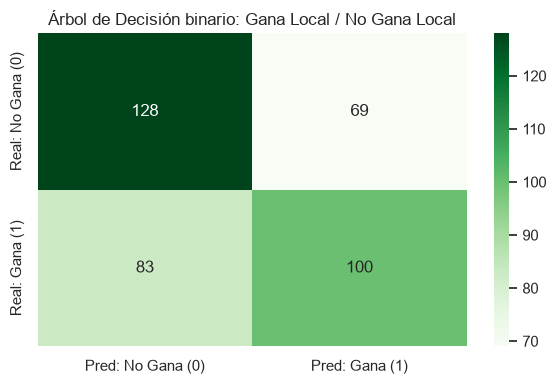

In [135]:
# Árbol de Decisión para gana local o no gana local
dt_binario = DecisionTreeClassifier(random_state=42)
tracemalloc.start()
inicio_dt_binario = time.time()
dt_binario.fit(X_train_def, y_train_binario)
y_pred_dt_binario = dt_binario.predict(X_test_def)
_, memoria_max_dt_binario = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_dt_binario = time.time() - inicio_dt_binario
ram_dt_binario_mb = memoria_max_dt_binario / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_dt_binario:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_dt_binario_mb:.4f} MB")
print(f"Accuracy Árbol de Decisión binario: {accuracy_score(y_test_binario, y_pred_dt_binario) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(
    y_test_binario, y_pred_dt_binario, labels=[0, 1],
    target_names=['No Gana Local (0)', 'Gana Local (1)'], zero_division=0
))

# Matriz de confusión
cm_dt_binario = confusion_matrix(y_test_binario, y_pred_dt_binario, labels=[0, 1])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_dt_binario, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Pred: No Gana (0)', 'Pred: Gana (1)'],
    yticklabels=['Real: No Gana (0)', 'Real: Gana (1)']
 )
plt.title('Árbol de Decisión binario: Gana Local / No Gana Local')
plt.tight_layout()
plt.show()

Tiempo de entrenamiento y predicción: 2.0680 segundos
Consumo máximo de memoria: 1.7018 MB
Accuracy Random Forest binario: 61.58%

Classification Report:
                   precision    recall  f1-score   support

No Gana Local (0)       0.61      0.70      0.65       197
   Gana Local (1)       0.62      0.53      0.57       183

         accuracy                           0.62       380
        macro avg       0.62      0.61      0.61       380
     weighted avg       0.62      0.62      0.61       380



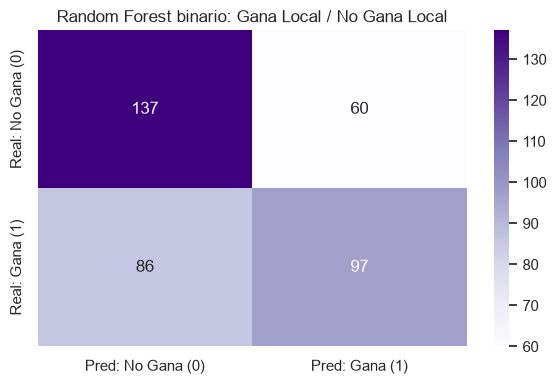

In [136]:
# Random Forest para gana local o no gana local
rf_binario = RandomForestClassifier(n_estimators=100, random_state=42)
tracemalloc.start()
inicio_rf_binario = time.time()
rf_binario.fit(X_train_def, y_train_binario)
y_pred_rf_binario = rf_binario.predict(X_test_def)
_, memoria_max_rf_binario = tracemalloc.get_traced_memory()
tracemalloc.stop()
tiempo_rf_binario = time.time() - inicio_rf_binario
ram_rf_binario_mb = memoria_max_rf_binario / (1024 * 1024)

print(f"Tiempo de entrenamiento y predicción: {tiempo_rf_binario:.4f} segundos")
print(f"Consumo máximo de memoria: {ram_rf_binario_mb:.4f} MB")
print(f"Accuracy Random Forest binario: {accuracy_score(y_test_binario, y_pred_rf_binario) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(
    y_test_binario, y_pred_rf_binario, labels=[0, 1],
    target_names=['No Gana Local (0)', 'Gana Local (1)'], zero_division=0
))

# Matriz de confusión
cm_rf_binario = confusion_matrix(y_test_binario, y_pred_rf_binario, labels=[0, 1])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf_binario, annot=True, fmt='d', cmap='Purples',
    xticklabels=['Pred: No Gana (0)', 'Pred: Gana (1)'],
    yticklabels=['Real: No Gana (0)', 'Real: Gana (1)']
 )
plt.title('Random Forest binario: Gana Local / No Gana Local')
plt.tight_layout()
plt.show()

Comparativa binaria: Gana Local / No Gana Local


,Modelo,Accuracy (%),Precision macro (%),Recall macro (%),F1 macro (%),Tiempo (s),Memoria (MB)
0,Reg. Logística,66.05,66.01,66.02,66.01,0.06,4.82
1,Naive Bayes,62.89,62.89,62.91,62.88,0.15,6.46
3,Random Forest,61.58,61.61,61.27,61.15,2.07,1.70
2,Árbol Decisión,60.00,59.92,59.81,59.78,0.08,1.85


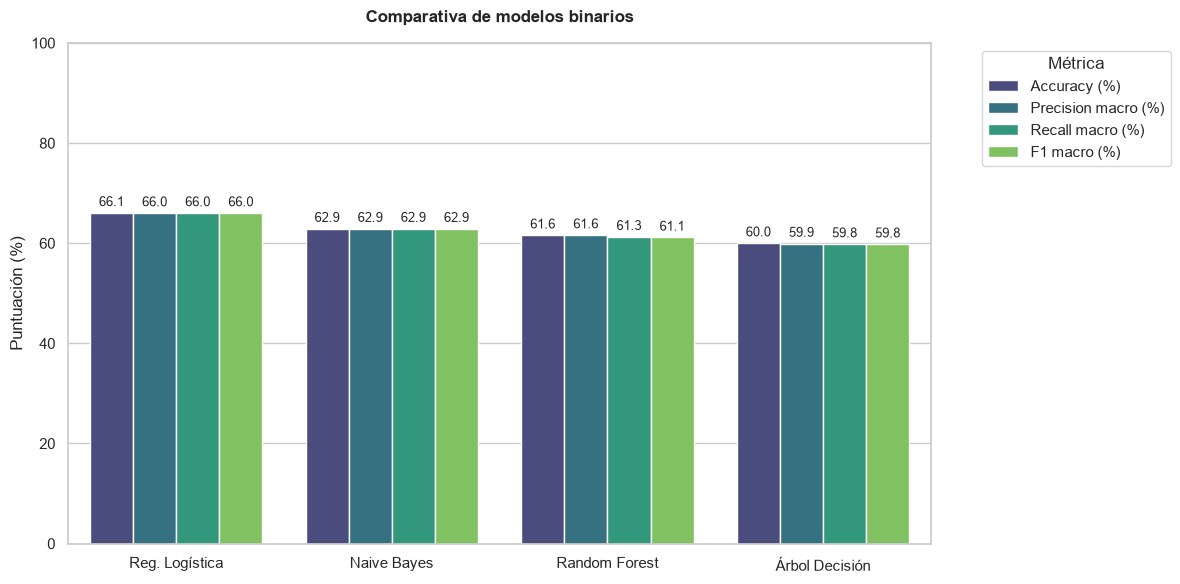

In [137]:
# Comparo los cuatro modelos binarios
modelos_binarios = [
    'Reg. Logística', 'Naive Bayes', 'Árbol Decisión', 'Random Forest'
 ]
predicciones_binarias = [
    y_pred_binario, y_pred_nb_binario, y_pred_dt_binario, y_pred_rf_binario
 ]
tiempos_binarios = [
    tiempo_lr_binario, tiempo_nb_binario, tiempo_dt_binario, tiempo_rf_binario
 ]
memorias_binarias = [
    ram_lr_binario_mb, ram_nb_binario_mb, ram_dt_binario_mb, ram_rf_binario_mb
 ]

metricas_binarias = []
for nombre_modelo, prediccion, tiempo, memoria in zip(
    modelos_binarios, predicciones_binarias, tiempos_binarios, memorias_binarias
 ):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test_binario, prediccion, average='macro', zero_division=0
    )
    metricas_binarias.append({
        'Modelo': nombre_modelo,
        'Accuracy (%)': accuracy_score(y_test_binario, prediccion) * 100,
        'Precision macro (%)': precision * 100,
        'Recall macro (%)': recall * 100,
        'F1 macro (%)': f1 * 100,
        'Tiempo (s)': tiempo,
        'Memoria (MB)': memoria
    })

df_resultados_binarios = pd.DataFrame(metricas_binarias).sort_values(
    by='Accuracy (%)', ascending=False
 )
print("Comparativa binaria: Gana Local / No Gana Local")
display(df_resultados_binarios.round(2))

# Grafico accuracy y métricas macro
df_metricas_binarias = df_resultados_binarios.melt(
    id_vars='Modelo',
    value_vars=['Accuracy (%)', 'Precision macro (%)', 'Recall macro (%)', 'F1 macro (%)'],
    var_name='Métrica',
    value_name='Porcentaje (%)'
 )
plt.figure(figsize=(12, 6))
sns.set_theme(style='whitegrid')
ax = sns.barplot(
    data=df_metricas_binarias, x='Modelo', y='Porcentaje (%)',
    hue='Métrica', palette='viridis'
 )
plt.title('Comparativa de modelos binarios', fontweight='bold', pad=15)
plt.ylabel('Puntuación (%)')
plt.xlabel('')
plt.ylim(0, 100)
plt.legend(title='Métrica', bbox_to_anchor=(1.05, 1), loc='upper left')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=9)
plt.tight_layout()
plt.show()

### Comparación contra las casas de apuestas

Una cuota no es una probabilidad. Para compararla con la probabilidad del modelo, convierto cada cuota en probabilidad implícita (`1 / cuota`) y la divido entre la suma de las tres probabilidades del partido (local, empate y visitante). Así elimino el margen que se queda la casa. Con eso mido la *accuracy* y el *LogLoss* del modelo y de cada casa en los mismos partidos de `2015/2016`. El *LogLoss* castiga las probabilidades mal calibradas, por eso mide la calidad de las probabilidades y no solo si el modelo acertó.

> **Limitación:** cada club juega 19 partidos como local, así que la eficacia por club cambia mucho con pocos partidos y no la tomo como un ranking confiable. Además, solo comparo contra las casas que tienen cuotas en `2015/2016`.

In [ ]:
# Defino las casas de apuestas que voy a comparar
casas = ['B365', 'BW', 'IW', 'LB', 'PS', 'WH', 'SJ', 'VC', 'GB', 'BS']
cols_cuotas = [f'{casa}{resultado}' for casa in casas for resultado in ['H', 'D', 'A']]

# Cargo los nombres de los equipos
df_teams = pd.read_csv('../data/processed/clean/Team_Clean.csv')
diccionario_equipos = df_teams.set_index('team_api_id')['team_long_name'].to_dict()

# Construyo la tabla de evaluación con los partidos de 2015/2016
idx_test = X_test_def.index
df_eval = pd.DataFrame({
    'match_api_id': df_calidad.loc[idx_test, 'match_api_id'].values,
    'home_team_api_id': df_calidad.loc[idx_test, 'home_team_api_id'].values,
    'Prob_Modelo_GanaLocal': lr_binario.predict_proba(X_test_def)[:, 1],
    'Prediccion': y_pred_binario,
    'Real': y_test_binario.values,
 })
df_cuotas = df_calidad.loc[idx_test, cols_cuotas].reset_index(drop=True)
df_eval = pd.concat([df_eval, df_cuotas], axis=1)
df_eval['Acierto'] = df_eval['Prediccion'] == df_eval['Real']
df_eval['Equipo_Local'] = df_eval['home_team_api_id'].map(diccionario_equipos)

# Convierto las cuotas en probabilidad de que gane el local, sin el margen de la casa
for casa in casas:
    suma_inversos = 1 / df_eval[f'{casa}H'] + 1 / df_eval[f'{casa}D'] + 1 / df_eval[f'{casa}A']
    df_eval[f'Prob_{casa}'] = (1 / df_eval[f'{casa}H']) / suma_inversos

# Reviso qué casas tienen cuotas en la temporada de prueba
casas_sin_cuotas = [casa for casa in casas if df_eval[f'Prob_{casa}'].isna().all()]
casas_con_cuotas = [casa for casa in casas if casa not in casas_sin_cuotas]

# Creo la mejor cuota, la cuota promedio y la probabilidad de consenso del mercado
cols_H = [f'{casa}H' for casa in casas_con_cuotas]
cols_prob = [f'Prob_{casa}' for casa in casas_con_cuotas]
df_eval['Cuota_Max_H'] = df_eval[cols_H].max(axis=1)
df_eval['Cuota_Prom_H'] = df_eval[cols_H].mean(axis=1)
df_eval['Prob_Mercado'] = df_eval[cols_prob].mean(axis=1)

# Comparo el modelo contra cada casa y contra el consenso, en los mismos partidos
y = df_eval['Real']
fuentes = {casa: f'Prob_{casa}' for casa in casas_con_cuotas}
fuentes['Consenso'] = 'Prob_Mercado'

filas = []
for nombre_fuente, columna in fuentes.items():
    con_cuota = df_eval[columna].notna()
    p_casa = df_eval.loc[con_cuota, columna]
    p_modelo = df_eval.loc[con_cuota, 'Prob_Modelo_GanaLocal']
    filas.append({
        'Fuente': nombre_fuente,
        'Partidos': int(con_cuota.sum()),
        'Accuracy casa (%)': ((p_casa > 0.5) == y[con_cuota]).mean() * 100,
        'Accuracy modelo (%)': ((p_modelo > 0.5) == y[con_cuota]).mean() * 100,
        'LogLoss casa': log_loss(y[con_cuota], p_casa),
        'LogLoss modelo': log_loss(y[con_cuota], p_modelo)
    })

print(f"Partidos de prueba: {len(df_eval)}")
print(f"Casas sin cuotas en 2015/2016: {', '.join(casas_sin_cuotas) or 'ninguna'}")
print(f"Baseline (siempre 'no gana'): {(1 - y.mean()) * 100:.2f}%")
print("\nModelo contra las casas de apuestas (LogLoss: menor es mejor):")
display(pd.DataFrame(filas).round(3))

# Calculo la eficacia del modelo por club cuando juega de local
eficacia_equipo = df_eval.groupby('Equipo_Local').agg(
    Partidos=('Acierto', 'count'),
    Aciertos=('Acierto', 'sum')
 )
eficacia_equipo['Eficacia (%)'] = eficacia_equipo['Aciertos'] / eficacia_equipo['Partidos'] * 100
eficacia_equipo = eficacia_equipo.sort_values(by='Eficacia (%)', ascending=False)

print("\nTop 5 de equipos más predecibles como locales:")
display(eficacia_equipo.head(5).round(2))
print("\nTop 5 de equipos menos predecibles como locales:")
display(eficacia_equipo.tail(5).round(2))

# Guardo la evaluación para usarla después
df_eval.to_csv('../data/processed/Evaluacion_Apuestas_Binario.csv', index=False)
print("\nEvaluación guardada como Evaluacion_Apuestas_Binario.csv")

### Auditoría multiclase: modelo contra cuotas

Para revisar partido por partido las tres probabilidades (local, empate y visitante), guardo una tabla de auditoría con el resultado real, la predicción del modelo y las cuotas de cuatro casas (`B365`, `IW`, `WH` y `VC`). Uso el modelo con identidad y fuerza de plantilla (`lr_hibrido`); si quiero auditar otro modelo, solo cambio las tres primeras líneas de la celda.

In [ ]:
# Defino el modelo y la matriz de prueba que voy a auditar
modelo_auditoria = lr_hibrido
X_test_auditoria = X_test_hibrido
y_pred_auditoria = y_pred_lr_hibrido

# Extraigo las probabilidades del modelo en el orden de sus clases
probabilidades = modelo_auditoria.predict_proba(X_test_auditoria)
clases = list(modelo_auditoria.classes_)
prob_L = probabilidades[:, clases.index('L')]
prob_E = probabilidades[:, clases.index('E')]
prob_V = probabilidades[:, clases.index('V')]
print(f"Probabilidades extraídas para {len(probabilidades)} partidos.")

# Selecciono el resultado real y las cuotas de cuatro casas en los partidos de prueba
cols_apuestas = [
    'match_api_id', 'home_team_api_id', 'away_team_api_id',
    'B365H', 'B365D', 'B365A',
    'IWH', 'IWD', 'IWA',
    'WHH', 'WHD', 'WHA',
    'VCH', 'VCD', 'VCA',
    'Resultado'
 ]
df_auditoria = df_calidad.loc[X_test_auditoria.index, cols_apuestas].copy()

# Agrego las probabilidades del modelo en porcentaje y su predicción
df_auditoria['Prob_ML_GanaLocal'] = (prob_L * 100).round(2)
df_auditoria['Prob_ML_Empate'] = (prob_E * 100).round(2)
df_auditoria['Prob_ML_GanaVisita'] = (prob_V * 100).round(2)
df_auditoria['Prediccion_ML'] = y_pred_auditoria

# Agrego los nombres de los equipos con el diccionario de la celda anterior
df_auditoria['Equipo_Local'] = df_auditoria['home_team_api_id'].map(diccionario_equipos)
df_auditoria['Equipo_Visitante'] = df_auditoria['away_team_api_id'].map(diccionario_equipos)

# Ordeno las columnas para comparar el modelo contra las cuotas
columnas_finales = [
    'match_api_id', 'Equipo_Local', 'Equipo_Visitante',
    'Resultado', 'Prediccion_ML',
    'Prob_ML_GanaLocal', 'Prob_ML_Empate', 'Prob_ML_GanaVisita',
    'B365H', 'B365D', 'B365A',
    'IWH', 'IWD', 'IWA',
    'WHH', 'WHD', 'WHA',
    'VCH', 'VCD', 'VCA'
 ]
df_auditoria = df_auditoria[columnas_finales]

print("\nVista previa de la auditoría (modelo contra cuotas):")
display(df_auditoria.head(10))

# Guardo la tabla de auditoría
df_auditoria.to_csv('Auditoria_ML_vs_CasasApuestas.csv', index=False)
print("\nTabla de auditoría guardada como Auditoria_ML_vs_CasasApuestas.csv")

Con la misma conversión de cuotas a probabilidades, comparo el modelo multiclase contra cada casa y contra el consenso de las cuatro (el promedio de sus probabilidades sin margen). Agrego cuántas veces cada fuente elige el empate como resultado más probable.

In [ ]:
# Calculo el LogLoss de las tres clases a mano
def calcular_log_loss(y_real, probabilidades):
    return -(y_real * np.log(np.clip(probabilidades, 1e-15, 1))).sum(axis=1).mean()

# Preparo el resultado real y las probabilidades del modelo en escala de 0 a 1
resultados_multiclase = ['L', 'E', 'V']
y_real_multiclase = pd.get_dummies(df_auditoria['Resultado']).reindex(
    columns=resultados_multiclase, fill_value=0
 ).to_numpy(dtype=float)
prob_modelo_multiclase = df_auditoria[
    ['Prob_ML_GanaLocal', 'Prob_ML_Empate', 'Prob_ML_GanaVisita']
].to_numpy() / 100

# Convierto las cuotas de cada casa en probabilidades sin el margen
casas_multiclase = ['B365', 'IW', 'WH', 'VC']
probs_casas = {}
margenes = {}
for casa in casas_multiclase:
    inversos = 1 / df_auditoria[[f'{casa}H', f'{casa}D', f'{casa}A']].to_numpy()
    margenes[casa] = (inversos.sum(axis=1) - 1).mean() * 100
    probs_casas[casa] = inversos / inversos.sum(axis=1, keepdims=True)

# Creo el consenso como el promedio de las probabilidades de las cuatro casas
probs_casas['Consenso'] = np.mean([probs_casas[casa] for casa in casas_multiclase], axis=0)

# Comparo el modelo contra cada casa y contra el consenso
fuentes_multiclase = {'Modelo': prob_modelo_multiclase, **probs_casas}
resultado_real = df_auditoria['Resultado'].to_numpy()

filas_multiclase = []
for nombre_fuente, probabilidades_fuente in fuentes_multiclase.items():
    prediccion = np.array(resultados_multiclase)[probabilidades_fuente.argmax(axis=1)]
    filas_multiclase.append({
        'Fuente': nombre_fuente,
        'Margen medio (%)': margenes.get(nombre_fuente, np.nan),
        'Accuracy (%)': (prediccion == resultado_real).mean() * 100,
        'LogLoss': calcular_log_loss(y_real_multiclase, probabilidades_fuente),
        'Empates como más probable': int((prediccion == 'E').sum())
    })

print(f"Baseline (siempre gana el local): {(resultado_real == 'L').mean() * 100:.2f}%")
print("Comparativa multiclase: modelo contra casas de apuestas (LogLoss: menor es mejor)")
display(pd.DataFrame(filas_multiclase).round(3))

### Simulación de la tabla general 2015/2016

Convierto la predicción de cada partido en puntos (3 por victoria, 1 por empate y 0 por derrota), sumo los puntos de cada club como local y como visitante y comparo la tabla del modelo con la tabla real.

In [ ]:
# Convierto cada resultado en puntos para el local y el visitante (3, 1 y 0)
def calcular_puntos(df, columna_resultado, prefijo):
    df[f'Pts_Local_{prefijo}'] = np.where(
        df[columna_resultado] == 'L', 3,
        np.where(df[columna_resultado] == 'E', 1, 0)
     )
    df[f'Pts_Visita_{prefijo}'] = np.where(
        df[columna_resultado] == 'V', 3,
        np.where(df[columna_resultado] == 'E', 1, 0)
     )
    return df

# Calculo los puntos reales y los puntos que predijo el modelo
df_simulacion = df_auditoria.copy()
df_simulacion = calcular_puntos(df_simulacion, 'Resultado', 'Real')
df_simulacion = calcular_puntos(df_simulacion, 'Prediccion_ML', 'Modelo')

# Sumo los puntos de cada club como local y como visitante
pts_local_real = df_simulacion.groupby('Equipo_Local')['Pts_Local_Real'].sum()
pts_local_mod = df_simulacion.groupby('Equipo_Local')['Pts_Local_Modelo'].sum()
pts_visita_real = df_simulacion.groupby('Equipo_Visitante')['Pts_Visita_Real'].sum()
pts_visita_mod = df_simulacion.groupby('Equipo_Visitante')['Pts_Visita_Modelo'].sum()

# Consolido la tabla general y calculo la diferencia contra los puntos reales
tabla_final = pd.DataFrame({
    'Pts_Reales': pts_local_real + pts_visita_real,
    'Pts_Modelo_ML': pts_local_mod + pts_visita_mod
 }).fillna(0).astype(int)
tabla_final['Diferencia_Pts'] = tabla_final['Pts_Modelo_ML'] - tabla_final['Pts_Reales']

# Ordeno la tabla según los puntos del modelo
tabla_final = tabla_final.sort_values(by='Pts_Modelo_ML', ascending=False)
tabla_final = tabla_final.rename_axis('Club').reset_index()
tabla_final.index += 1
tabla_final.index.name = 'Posición ML'

print("Tabla general simulada contra la real:")
display(tabla_final)

# Guardo la tabla final
tabla_final.to_csv('Tabla_General_Simulada_15_16.csv')
print("\nTabla guardada como Tabla_General_Simulada_15_16.csv")

### Puntos esperados (xPts)

La tabla anterior usa la clase con mayor probabilidad, así que un equipo débil pierde todos sus partidos aunque el modelo le asigne probabilidad de empatar o ganar. Con las probabilidades completas calculo los puntos esperados de cada partido (`3 * P(victoria) + 1 * P(empate)`), los sumo por club y los comparo contra los puntos reales y contra la tabla anterior.

In [ ]:
# Calculo los puntos esperados de cada partido con las probabilidades del modelo
df_xpts = df_auditoria.copy()
df_xpts['xPts_Local'] = (3 * df_xpts['Prob_ML_GanaLocal'] + df_xpts['Prob_ML_Empate']) / 100
df_xpts['xPts_Visita'] = (3 * df_xpts['Prob_ML_GanaVisita'] + df_xpts['Prob_ML_Empate']) / 100

# Sumo los puntos esperados de cada club como local y como visitante
xpts_local = df_xpts.groupby('Equipo_Local')['xPts_Local'].sum()
xpts_visita = df_xpts.groupby('Equipo_Visitante')['xPts_Visita'].sum()

# Agrego los puntos esperados a la tabla simulada y calculo el error de cada enfoque
tabla_xpts = tabla_final.set_index('Club')[['Pts_Reales', 'Pts_Modelo_ML']].copy()
tabla_xpts['xPts_Modelo'] = xpts_local + xpts_visita
tabla_xpts['Error_Clasificacion'] = (tabla_xpts['Pts_Modelo_ML'] - tabla_xpts['Pts_Reales']).abs()
tabla_xpts['Error_xPts'] = (tabla_xpts['xPts_Modelo'] - tabla_xpts['Pts_Reales']).abs()
tabla_xpts = tabla_xpts.sort_values(by='xPts_Modelo', ascending=False)

print("Puntos reales, puntos por clasificación y puntos esperados:")
display(tabla_xpts.round(1))

# Resumo el error de cada enfoque contra los puntos reales
resumen_xpts = pd.DataFrame({
    'Enfoque': ['Clasificación (3, 1, 0)', 'Puntos esperados (xPts)'],
    'Puntos totales': [tabla_xpts['Pts_Modelo_ML'].sum(), tabla_xpts['xPts_Modelo'].sum()],
    'Error absoluto medio (pts)': [tabla_xpts['Error_Clasificacion'].mean(), tabla_xpts['Error_xPts'].mean()],
    'Correlación': [
        tabla_xpts['Pts_Modelo_ML'].corr(tabla_xpts['Pts_Reales']),
        tabla_xpts['xPts_Modelo'].corr(tabla_xpts['Pts_Reales'])
    ],
    'Correlación de rangos': [
        tabla_xpts['Pts_Modelo_ML'].corr(tabla_xpts['Pts_Reales'], method='spearman'),
        tabla_xpts['xPts_Modelo'].corr(tabla_xpts['Pts_Reales'], method='spearman')
    ]
 })
print(f"\nPuntos totales reales de la temporada: {tabla_xpts['Pts_Reales'].sum()}")
display(resumen_xpts.round(3))

# Grafico los puntos de cada enfoque contra los puntos reales
plt.figure(figsize=(8, 6))
sns.set_theme(style='whitegrid')
plt.scatter(
    tabla_xpts['Pts_Reales'], tabla_xpts['Pts_Modelo_ML'],
    label='Clasificación (3, 1, 0)', color='tab:red'
 )
plt.scatter(
    tabla_xpts['Pts_Reales'], tabla_xpts['xPts_Modelo'],
    label='Puntos esperados (xPts)', color='tab:blue'
 )
plt.plot([25, 115], [25, 115], color='gray', linestyle='--', label='Coincidencia exacta')
plt.title('Puntos reales contra puntos del modelo (2015/2016)', fontweight='bold', pad=15)
plt.xlabel('Puntos reales')
plt.ylabel('Puntos del modelo')
plt.legend()
plt.tight_layout()
plt.show()

### Conclusiones

En este notebook construí un predictor del resultado de los partidos de La Liga y lo amplié por etapas con identidad de equipos, fuerza de plantilla, forma reciente y táctica. Siempre entrené con las temporadas anteriores a `2015/2016` (2660 partidos) y evalué en esa temporada (380 partidos). También comparé el modelo contra las cuotas de las casas de apuestas y simulé la tabla general con sus predicciones.

| Etapa | Mejor modelo | Accuracy (%) |
|---|---|---|
| Solo identidad de los equipos | Reg. Logística | 52.89 |
| Identidad y fuerza de plantilla | Reg. Logística | 53.68 |
| Identidad, fuerza y forma | Reg. Logística | 54.74 |
| Identidad, fuerza, forma y táctica | Reg. Logística | 53.42 |
| Referencia: siempre gana el local | - | 48.16 |

### Lo que aprendí

**1. Agregar variables no mejoró el modelo de forma medible.** Entre la línea base con solo los IDs de los equipos (52.89%) y la mejor etapa (54.74%) hay menos de dos puntos, y con 380 partidos de prueba el margen de error del *accuracy* es de unos 5 puntos. La etapa táctica incluso bajó a 53.42%. Lo más probable es que la identidad del equipo ya contenga casi todo lo que aportan los ratings y las tácticas, porque los equipos fuertes y débiles tienden a mantenerse así de una temporada a otra.

**2. El mercado supera al modelo.** Con las cuotas convertidas a probabilidades sin margen, las casas tienen mejor *LogLoss* que el modelo: de 0.587 a 0.593 contra 0.602 en el enfoque binario, y de 0.926 a 0.934 contra 0.965 en el multiclase. Las cuotas incorporan información que mis datos no tienen, como lesiones, alineaciones probables y noticias, y mi modelo no muestra evidencia de saber algo que el mercado no sepa. Cualquier simulación de apuestas con estas probabilidades parte sin evidencia de ventaja.

**3. El empate no se resuelve forzando una clase.** El modelo acertó 4 de los 92 empates reales (*recall* de 4.3%), y ninguna de las cuatro casas tiene al empate como resultado más probable en alguno de los 380 partidos: su probabilidad máxima de empate va de 29.9% a 32.6%. El empate es el resultado más ambiguo del fútbol, por eso conviene trabajarlo con probabilidades.

**4. Una clasificación dura distorsiona la tabla, y las probabilidades la corrigen en parte.** Al convertir cada predicción en puntos, el modelo dejó a la SD Eibar en 0 puntos (logró 43) y sumó 1129 puntos contra 1048 reales, porque casi nunca asigna empates. Con puntos esperados (`3 * P(victoria) + 1 * P(empate)`) el error absoluto medio por club bajó de 13.65 a 6.75 puntos y el total quedó en 1057. No necesito un regresor para obtenerlos: las probabilidades del clasificador alcanzan. Aun así, el orden de los clubes casi no cambió (correlación de rangos de 0.740 a 0.742), es decir, los puntos esperados corrigen la escala pero no el orden. Por ejemplo, el modelo sobrestima al Valencia (62.7 puntos esperados contra 44 reales) y subestima al Atlético de Madrid (66.7 contra 88), lo que sugiere que el rating de una plantilla no explica por sí solo su rendimiento.

**5. Las métricas de este notebook son un techo optimista.** `Fuerza_*` usa el rating medio de toda la temporada y las tácticas se agrupan por año, así que algunas variables contienen información posterior al partido. Una evaluación prepartido real necesita datos con fecha.

### Lo que me llevo para el siguiente predictor

- Separar entrenamiento y prueba por temporada y ajustar el escalador solo con entrenamiento.
- Construir la forma reciente con `shift(1)` para que un partido no entre en su propia racha.
- Convertir las cuotas en probabilidades sin margen y comparar siempre contra el consenso de las casas con *LogLoss*, no solo con *accuracy*.
- Trabajar con probabilidades antes que con clases y usar los puntos esperados para simular temporadas.
- Guardar los modelos y las tablas intermedias entre notebooks; el KNN de posiciones tuvo que reentrenarse aquí porque no se guardó.

### Decisión: el predictor de partidos se hará con una base de datos nueva

Con estos resultados, el predictor de partidos final no lo haré con esta base de datos. Usaré una base nueva y más completa, y este notebook queda como prueba de concepto y registro de lo aprendido. Los motivos son estos:

1. **Falta de información (motivo principal).** Cada equipo se describe solo con ratings de videojuego, un perfil táctico por año y los goles de sus últimos cinco partidos. No hay lesiones ni sanciones, cambios de entrenador, fichajes ni métricas de rendimiento reales previas al partido como xG, tiros o pases progresivos. Las estadísticas del partido que sí trae la base (tiros, posesión y tarjetas) solo existen después de jugarlo, así que no sirven para predecir.
2. **Variables sin fecha.** Sin fecha en cada rating y en cada perfil táctico no puedo construir variables que usen solo lo disponible antes del partido, y eso deja toda la evaluación con fuga temporal.
3. **Muestra y ventana limitadas.** Son 3040 partidos de una sola liga con una sola temporada de prueba, y los datos terminan en `2015/2016`, así que el modelo no ve el fútbol actual.
4. **Cobertura de cuotas.** `SJ`, `GB` y `BS` no tienen cuotas en `2015/2016`, por lo que solo pude comparar contra siete casas.

En la base nueva voy a buscar:

- Fecha en cada partido y en cada dato, para calcular todas las variables con información previa al partido.
- Métricas de rendimiento por partido (xG, tiros, pases progresivos, presiones) para promediarlas antes de cada encuentro.
- Lesiones, sanciones y alineaciones lo más cercanas posible al inicio del partido.
- Más ligas y temporadas, con cuotas de apertura y de cierre completas, para evaluar con varias temporadas de prueba y comparar contra el mercado.